# Práctica integradora — Datos para Machine Learning
## Logística de entregas urbanas (CDMX) · Datos sintéticos

**Objetivo:** integrar cinco fuentes de datos, auditar su calidad, limpiarlas, seleccionar variables sin fuga de información y construir cuatro modelos (regresión lineal, árbol de decisión, reglas SI–ENTONCES y K-Means), evaluándolos con datos distintos a los de entrenamiento.

**Principio rector:** la predicción debe hacerse **al momento de crear el pedido**. Por eso toda variable que se conoce *después* (fecha de entrega, costo final, estado, encuesta, etc.) se trata como posible fuga de información.

**Índice**
1. Exploración de datos
2. Calidad de datos
3. Tipos de variables
4. Integración de datos
5. Limpieza de datos
6. Selección de variables
7. Transformación de datos
8. Construcción de modelos
9. Evaluación e interpretación
10. Guardado de datasets limpios
11. Conclusiones

## 0. Configuración
Se cargan las librerías y se localizan los archivos. En **Google Colab** basta con subir los CSV al panel de archivos (o ejecutar la celda y seleccionarlos cuando lo pida).

In [1]:
import os, re, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.cluster import KMeans
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, confusion_matrix,
                             ConfusionMatrixDisplay, precision_score, recall_score, f1_score,
                             accuracy_score, roc_auc_score, silhouette_score)
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)
pd.set_option('display.max_colwidth', 60)
sns.set_theme(style='whitegrid')
SEED = 42

NOMBRES = ['01_pedidos_bd.csv', '02_lecturas_sensores.csv', '03_clientes_bd.csv',
           '04_catalogo_zonas.csv', '05_encuestas_postentrega.csv']
CANDIDATOS = ['.', '/content', '/content/sample_data', '/content/drive/MyDrive', '/mnt/user-data/uploads']
DIR = next((d for d in CANDIDATOS if all(os.path.exists(os.path.join(d, n)) for n in NOMBRES)), None)
if DIR is None:
    try:
        from google.colab import files
        print('Selecciona los archivos CSV del dataset (01 a 05, y opcionalmente el 06 de clima)...')
        files.upload()
        DIR = '.'
    except ImportError:
        raise FileNotFoundError('No se encontraron los CSV. Colócalos junto al notebook.')
print('Carpeta de datos:', DIR)

# Bitácora de limpieza (antes/después) que se exporta al final
bitacora = []
def log(paso, fuente, columna, problema, accion, afectados, antes, despues, justificacion):
    bitacora.append(dict(paso=paso, fuente=fuente, columna=columna, problema=problema, accion=accion,
                         registros_afectados=int(afectados), antes=str(antes), despues=str(despues),
                         justificacion=justificacion))

Carpeta de datos: .


## 1. Exploración de datos
Se cargan los archivos **tal como vienen** (sin corregir nada) con codificación `utf-8-sig` (los archivos traen BOM). `distancia_km` se lee como texto porque contiene formatos mezclados.

In [2]:
pedidos_raw    = pd.read_csv(f'{DIR}/01_pedidos_bd.csv', encoding='utf-8-sig', dtype={'distancia_km': str})
sensores_raw   = pd.read_csv(f'{DIR}/02_lecturas_sensores.csv', encoding='utf-8-sig')
clientes_raw   = pd.read_csv(f'{DIR}/03_clientes_bd.csv', encoding='utf-8-sig')
zonas_raw      = pd.read_csv(f'{DIR}/04_catalogo_zonas.csv', encoding='utf-8-sig')
encuestas_raw  = pd.read_csv(f'{DIR}/05_encuestas_postentrega.csv', encoding='utf-8-sig')
ruta_clima     = os.path.join(DIR, '06_reporte_externo_clima.txt')
clima_raw = pd.read_csv(ruta_clima, sep=';', encoding='utf-8-sig') if os.path.exists(ruta_clima) else None


fuentes = {'01 pedidos': pedidos_raw, '02 sensores': sensores_raw, '03 clientes': clientes_raw,
           '04 zonas': zonas_raw, '05 encuestas': encuestas_raw, '06 clima': clima_raw}

resumen = pd.DataFrame({n: {'registros': d.shape[0], 'columnas': d.shape[1],
                            'nulos totales': int(d.isna().sum().sum()),
                            'filas duplicadas': int(d.duplicated().sum())} for n, d in fuentes.items()}).T
resumen

,registros,columnas,nulos totales,filas duplicadas
01 pedidos,12220,16,574,220
02 sensores,24280,8,898,280
03 clientes,2580,5,535,80
04 zonas,6,5,0,0
05 encuestas,12140,5,747,140
06 clima,720,3,0,0


In [3]:
def explorar(nombre, df):
    print(f'{nombre}: {df.shape[0]:,} registros x {df.shape[1]} columnas');
    info = pd.DataFrame({'tipo (pandas)': df.dtypes.astype(str), 'nulos': df.isna().sum(),
                         '% nulos': (100*df.isna().mean()).round(2), 'únicos': df.nunique(),
                         'ejemplo': df.iloc[0]})
    display(info)

for n, d in fuentes.items():
    explorar(n, d)

01 pedidos: 12,220 registros x 16 columnas


,tipo (pandas),nulos,% nulos,únicos,ejemplo
pedido_id,object,0,0.00,12000,P00001
cliente_id,object,0,0.00,2482,C1180
zona_id,object,0,0.00,7,Z06
fecha_pedido,object,0,0.00,11163,2026-07-14 12:03
tipo_servicio,object,0,0.00,2,Exprés
prioridad,object,35,0.29,8,Alta
distancia_km,object,299,2.45,2464,24.99
numero_paquetes,int64,0,0.00,11,6
peso_kg,float64,240,1.96,1235,3.72
tiempo_prometido_min,float64,0,0.00,838,92.8


02 sensores: 24,280 registros x 8 columnas


,tipo (pandas),nulos,% nulos,únicos,ejemplo
lectura_id,object,0,0.00,24000,L00001_0
pedido_id,object,0,0.00,12000,P00001
fecha_lectura,object,0,0.00,21424,2026-07-14 12:03:00
temperatura_c,float64,0,0.00,23733,17.627256
indice_trafico,object,597,2.46,1028,53.0
humedad_pct,float64,0,0.00,808,80.8
lluvia_detectada,int64,0,0.00,2,1
dispositivo_id,object,301,1.24,48,SEN-06-02


03 clientes: 2,580 registros x 5 columnas


...

,tipo (pandas),nulos,% nulos,únicos,ejemplo
zona_id,object,0,0.0,6,Z01
zona,object,0,0.0,6,Norte
distancia_centro_km,int64,0,0.0,6,8
factor_trafico_historico,float64,0,0.0,6,1.05
ultima_actualizacion,object,0,0.0,2,2026-09-30


05 encuestas: 12,140 registros x 5 columnas


,tipo (pandas),nulos,% nulos,únicos,ejemplo
pedido_id,object,0,0.00,12000,P00001
puntuacion_entrega,float64,747,6.15,6,3.0
recomendaria,object,0,0.00,2,No
comentario,object,0,0.00,5,Buen servicio
fecha_encuesta,object,0,0.00,127,2026-07-18


06 clima: 720 registros x 3 columnas


,tipo (pandas),nulos,% nulos,únicos,ejemplo
fecha,object,0,0.0,120,01/07/2026
zona_id,object,0,0.0,6,Z01
alerta_climatica,object,0,0.0,4,Lluvia


In [4]:
# Estadísticos descriptivos de las columnas numéricas de cada fuente
for n, d in fuentes.items():
    num = d.select_dtypes(include='number')
    if num.shape[1]:
        print(f'{n}'); display(num.describe().T.round(2))

01 pedidos


,count,mean,std,min,25%,50%,75%,max
numero_paquetes,12220.0,5.11,9.94,-2.0,2.00,5.00,7.00,150.00
peso_kg,11980.0,16.30,112.27,-1.0,2.65,3.88,5.63,1300.00
tiempo_prometido_min,12220.0,56.65,17.51,18.0,43.80,56.40,69.30,111.40
tiempo_real_min,12220.0,57.32,21.27,8.0,42.10,56.90,72.00,131.60
entrega_tardia,12220.0,0.34,0.47,0.0,0.00,0.00,1.00,1.00
costo_final_mxn,12220.0,212.55,56.93,62.0,171.10,210.76,253.28,417.09


02 sensores


,count,mean,std,min,25%,50%,75%,max
temperatura_c,24280.0,27.65,60.40,-80.0,20.62,24.04,27.52,999.0
humedad_pct,24280.0,57.64,16.61,-2.0,47.30,57.30,67.60,140.0
lluvia_detectada,24280.0,0.30,0.46,0.0,0.00,0.00,1.00,1.0


03 clientes


,count,mean,std,min,25%,50%,75%,max
antiguedad_meses,2580.0,24.52,15.22,-2.0,12.0,25.0,38.0,50.0
satisfaccion_previa,2045.0,3.01,1.45,1.0,2.0,3.0,4.0,5.0


04 zonas


,count,mean,std,min,25%,50%,75%,max
distancia_centro_km,6.0,12.0,4.73,6.00,8.75,12.0,14.50,19.00
factor_trafico_historico,6.0,1.2,0.12,1.05,1.13,1.2,1.29,1.35


05 encuestas


,count,mean,std,min,25%,50%,75%,max
puntuacion_entrega,11393.0,4.06,1.19,1.0,3.0,4.0,5.0,7.0


**Lectura rápida de la exploración**
- `pedidos` tiene filas repetidas y `distancia_km` quedó como texto (hay formatos como `12,5`, `8 km`, `n/d`).
- `sensores` tiene **dos lecturas por pedido** (granularidad más fina que pedidos) y rangos físicamente imposibles (p. ej. temperatura de 999 °C).
- `clientes` y `encuestas` traen identificadores repetidos; `zonas` es un catálogo de solo 6 filas.

## 2. Calidad de datos
Se evalúan los seis criterios pedidos: **completitud, unicidad, consistencia, validez, exactitud y actualidad**. Cada hallazgo registra el número y porcentaje de registros afectados y se muestran dos ejemplos. *Un valor extremo no se asume como error:* se distingue entre valores **imposibles** (validez) y valores **atípicos plausibles** (exactitud).

In [5]:
p, s, c, z, e = pedidos_raw, sensores_raw, clientes_raw, zonas_raw, encuestas_raw

hallazgos, ejemplos = [], {}
def hallazgo(criterio, fuente, columna, problema, df, mask, cols):
    mask = mask.fillna(False).astype(bool)
    hallazgos.append(dict(criterio=criterio, fuente=fuente, columna=columna, problema=problema,
                          registros=int(mask.sum()), total=len(df), pct=round(100*mask.mean(), 2)))
    ejemplos[(criterio, fuente, problema)] = df.loc[mask, cols].head(2)

# Versiones auxiliares (solo para auditar; no modifican los datos crudos)
dist_txt = p['distancia_km']
dist_num = pd.to_numeric(dist_txt, errors='coerce')
fp = pd.to_datetime(p['fecha_pedido'], format='%Y-%m-%d %H:%M', errors='coerce')
fe = pd.to_datetime(p['fecha_entrega'], format='%Y-%m-%d %H:%M', errors='coerce')
ti_txt = s['indice_trafico']
ti_num = pd.to_numeric(ti_txt, errors='coerce')
es_nd = lambda x: x.astype(str).str.strip().str.lower().isin(['n/d', 's/f', 'nan', 'none', ''])
OK_PRIO = ['Baja', 'Media', 'Alta']

# ---- COMPLETITUD
hallazgo('Completitud', 'pedidos', 'prioridad', 'prioridad vacía', p, p['prioridad'].isna(), ['pedido_id', 'prioridad'])
hallazgo('Completitud', 'pedidos', 'distancia_km', "distancia vacía o 'n/d'", p, es_nd(dist_txt), ['pedido_id', 'distancia_km'])
hallazgo('Completitud', 'pedidos', 'peso_kg', 'peso vacío', p, p['peso_kg'].isna(), ['pedido_id', 'peso_kg'])
hallazgo('Completitud', 'pedidos', 'fecha_pedido', "fecha de pedido faltante ('s/f')", p, p['fecha_pedido'].astype(str).str.lower().eq('s/f'), ['pedido_id', 'fecha_pedido', 'fecha_entrega'])
hallazgo('Completitud', 'sensores', 'indice_trafico', "índice de tráfico vacío o 'N/D'", s, ti_txt.isna() | ti_txt.astype(str).str.upper().eq('N/D'), ['lectura_id', 'indice_trafico'])
hallazgo('Completitud', 'sensores', 'dispositivo_id', 'dispositivo sin identificar', s, s['dispositivo_id'].isna(), ['lectura_id', 'dispositivo_id'])
hallazgo('Completitud', 'clientes', 'satisfaccion_previa', 'satisfacción previa vacía', c, c['satisfaccion_previa'].isna(), ['cliente_id', 'satisfaccion_previa'])
hallazgo('Completitud', 'encuestas', 'puntuacion_entrega', 'puntuación vacía', e, e['puntuacion_entrega'].isna(), ['pedido_id', 'puntuacion_entrega'])

# ---- UNICIDAD
hallazgo('Unicidad', 'pedidos', 'pedido_id', 'pedido repetido (fila idéntica)', p, p.duplicated(), ['pedido_id', 'cliente_id', 'fecha_pedido'])
hallazgo('Unicidad', 'sensores', 'lectura_id', 'lectura repetida (fila idéntica)', s, s.duplicated(), ['lectura_id', 'pedido_id', 'fecha_lectura'])
hallazgo('Unicidad', 'clientes', 'cliente_id', 'cliente repetido (fila idéntica)', c, c.duplicated(), ['cliente_id', 'tipo_cliente'])
hallazgo('Unicidad', 'encuestas', 'pedido_id', 'encuesta repetida (fila idéntica)', e, e.duplicated(), ['pedido_id', 'puntuacion_entrega'])

# ---- CONSISTENCIA (formatos y reglas entre columnas)
hallazgo('Consistencia', 'pedidos', 'prioridad', 'categoría con variantes (ALTA, media, " BAJA ", Medio)', p, p['prioridad'].notna() & ~p['prioridad'].isin(OK_PRIO), ['pedido_id', 'prioridad'])
hallazgo('Consistencia', 'clientes', 'tipo_cliente', 'categoría con variantes (Recurr., empresa, " nuevo ")', c, ~c['tipo_cliente'].isin(['Recurrente', 'Nuevo', 'Empresa']), ['cliente_id', 'tipo_cliente'])
hallazgo('Consistencia', 'pedidos', 'distancia_km', "formato numérico mezclado ('12,5', '8 km')", p, dist_num.isna() & dist_txt.notna() & ~es_nd(dist_txt), ['pedido_id', 'distancia_km'])
hallazgo('Consistencia', 'sensores', 'indice_trafico', "texto en columna numérica ('alto')", s, ti_num.isna() & ti_txt.notna() & ~ti_txt.astype(str).str.upper().eq('N/D'), ['lectura_id', 'indice_trafico'])
hallazgo('Consistencia', 'pedidos', 'fecha_pedido', "fecha con formato o calendario inválido ('31/02/2026', '2026/99/12')", p, fp.isna() & p['fecha_pedido'].notna() & ~es_nd(p['fecha_pedido']), ['pedido_id', 'fecha_pedido'])
dif_fechas = (fe - fp).dt.total_seconds()/60 - p['tiempo_real_min']
hallazgo('Consistencia', 'pedidos', 'fecha_entrega - fecha_pedido', 'duración por fechas ≠ tiempo_real_min (±1 min)', p, dif_fechas.abs() > 1, ['pedido_id', 'fecha_pedido', 'fecha_entrega', 'tiempo_real_min'])
hallazgo('Consistencia', 'pedidos', 'entrega_tardia', 'etiqueta ≠ regla (real - prometido > 5 min)', p, ((p['tiempo_real_min'] - p['tiempo_prometido_min']) > 5).astype(int) != p['entrega_tardia'], ['pedido_id', 'tiempo_prometido_min', 'tiempo_real_min', 'entrega_tardia'])
hallazgo('Consistencia', 'pedidos', 'estado_entrega', 'estado_entrega ≠ entrega_tardia', p, (p['estado_entrega'].eq('Tarde')).astype(int) != p['entrega_tardia'], ['pedido_id', 'estado_entrega', 'entrega_tardia'])

# ---- VALIDEZ (valores fuera del dominio posible)
hallazgo('Validez', 'pedidos', 'numero_paquetes', 'número de paquetes ≤ 0', p, p['numero_paquetes'] <= 0, ['pedido_id', 'numero_paquetes'])
hallazgo('Validez', 'pedidos', 'numero_paquetes', 'número de paquetes = 150 (centinela, el resto va de 1 a 8)', p, p['numero_paquetes'] > 50, ['pedido_id', 'numero_paquetes'])
hallazgo('Validez', 'pedidos', 'peso_kg', 'peso ≤ 0', p, p['peso_kg'] <= 0, ['pedido_id', 'peso_kg'])
hallazgo('Validez', 'pedidos', 'peso_kg', 'peso > 100 kg (700 / 1300: centinelas o error de unidad)', p, p['peso_kg'] > 100, ['pedido_id', 'peso_kg'])
hallazgo('Validez', 'sensores', 'temperatura_c', 'temperatura fuera de [-5, 45] °C (-80 / 999)', s, (s['temperatura_c'] < -5) | (s['temperatura_c'] > 45), ['lectura_id', 'temperatura_c'])
hallazgo('Validez', 'sensores', 'humedad_pct', 'humedad fuera de [0, 100] %', s, (s['humedad_pct'] < 0) | (s['humedad_pct'] > 100), ['lectura_id', 'humedad_pct'])
hallazgo('Validez', 'sensores', 'indice_trafico', 'índice de tráfico fuera de [0, 100]', s, (ti_num < 0) | (ti_num > 100), ['lectura_id', 'indice_trafico'])
hallazgo('Validez', 'clientes', 'antiguedad_meses', 'antigüedad negativa', c, c['antiguedad_meses'] < 0, ['cliente_id', 'antiguedad_meses'])
hallazgo('Validez', 'encuestas', 'puntuacion_entrega', 'puntuación fuera de la escala 1–5 (valor 7)', e, e['puntuacion_entrega'].notna() & ~e['puntuacion_entrega'].between(1, 5), ['pedido_id', 'puntuacion_entrega'])
hallazgo('Validez', 'pedidos', 'zona_id', 'zona inexistente en el catálogo (Z99)', p, ~p['zona_id'].isin(z['zona_id']), ['pedido_id', 'zona_id'])
hallazgo('Validez', 'pedidos', 'cliente_id', 'cliente inexistente en clientes (C9999)', p, ~p['cliente_id'].isin(c['cliente_id']), ['pedido_id', 'cliente_id'])

# ---- EXACTITUD (atípicos plausibles: se revisan, NO se asumen error)
def fence(x, k=1.5):
    q1, q3 = x.quantile([.25, .75]); i = q3 - q1; return q1 - k*i, q3 + k*i
lo, hi = fence(p['tiempo_real_min'])
hallazgo('Exactitud', 'pedidos', 'tiempo_real_min', 'valor extremo por IQR (plausible: pedidos largos)', p, (p['tiempo_real_min'] < lo) | (p['tiempo_real_min'] > hi), ['pedido_id', 'distancia_km', 'tiempo_prometido_min', 'tiempo_real_min'])
lo, hi = fence(p['costo_final_mxn'])
hallazgo('Exactitud', 'pedidos', 'costo_final_mxn', 'valor extremo por IQR (plausible: servicios caros)', p, (p['costo_final_mxn'] < lo) | (p['costo_final_mxn'] > hi), ['pedido_id', 'distancia_km', 'costo_final_mxn'])
lo, hi = fence(p.loc[p['peso_kg'].between(0.01, 100), 'peso_kg'])
hallazgo('Exactitud', 'pedidos', 'peso_kg', 'peso alto pero plausible (20–100 kg)', p, p['peso_kg'].between(20, 100), ['pedido_id', 'numero_paquetes', 'peso_kg'])

# ---- ACTUALIDAD
hallazgo('Actualidad', 'zonas', 'ultima_actualizacion', 'registro de catálogo sin actualizar desde 2018 (resto: 2026-09-30)', z, pd.to_datetime(z['ultima_actualizacion']) < '2026-01-01', ['zona_id', 'zona', 'factor_trafico_historico', 'ultima_actualizacion'])
enc_chk = e.drop_duplicates().merge(p.drop_duplicates()[['pedido_id', 'fecha_entrega']].drop_duplicates('pedido_id'), on='pedido_id', how='left')
dias_enc = (pd.to_datetime(enc_chk['fecha_encuesta']) - pd.to_datetime(enc_chk['fecha_entrega'])).dt.days
hallazgo('Actualidad', 'encuestas', 'fecha_encuesta', 'encuesta anterior a la entrega', enc_chk, dias_enc < 0, ['pedido_id', 'fecha_encuesta', 'fecha_entrega'])
hallazgo('Actualidad', 'pedidos', 'zona_id', 'pedidos que dependen del registro de catálogo desactualizado (Z06)', p, p['zona_id'].eq('Z06'), ['pedido_id', 'zona_id', 'fecha_pedido'])

tabla_calidad = pd.DataFrame(hallazgos)
orden = ['Completitud', 'Unicidad', 'Consistencia', 'Validez', 'Exactitud', 'Actualidad']
tabla_calidad['criterio'] = pd.Categorical(tabla_calidad['criterio'], orden, ordered=True)
tabla_calidad = tabla_calidad.sort_values(['criterio', 'fuente']).reset_index(drop=True)
tabla_calidad

,criterio,fuente,columna,problema,registros,total,pct
0,Completitud,clientes,satisfaccion_previa,satisfacción previa vacía,535,2580,20.74
1,Completitud,encuestas,puntuacion_entrega,puntuación vacía,747,12140,6.15
2,Completitud,pedidos,prioridad,prioridad vacía,35,12220,0.29
3,Completitud,pedidos,distancia_km,distancia vacía o 'n/d',384,12220,3.14
4,Completitud,pedidos,peso_kg,peso vacío,240,12220,1.96
5,Completitud,pedidos,fecha_pedido,fecha de pedido faltante ('s/f'),65,12220,0.53
6,Completitud,sensores,indice_trafico,índice de tráfico vacío o 'N/D',663,24280,2.73
7,Completitud,sensores,dispositivo_id,dispositivo sin identificar,301,24280,1.24
8,Unicidad,clientes,cliente_id,cliente repetido (fila idéntica),80,2580,3.10
9,Unicidad,encuestas,pedido_id,encuesta repetida (fila idéntica),140,12140,1.15


In [6]:
# Resumen por criterio y 2 ejemplos por hallazgo
resumen_criterio = tabla_calidad.groupby('criterio', observed=True).agg(
    hallazgos=('problema', 'count'),
    hallazgos_con_casos=('registros', lambda x: int((x > 0).sum())),
    registros_afectados_max=('registros', 'max'), pct_max=('pct', 'max'))
display(resumen_criterio)

for criterio in orden:
    print(f'CRITERIO: {criterio.upper()} — 2 ejemplos por hallazgo')
    for (cr, fuente, prob), ej in ejemplos.items():
        if cr == criterio:
            n = int(tabla_calidad.query('criterio == @cr and fuente == @fuente and problema == @prob')['registros'].iloc[0])
            print(f'\n[{fuente}] {prob}  ->  {n:,} registros')
            display(ej if len(ej) else pd.DataFrame({'resultado': ['Sin casos: la verificación no encontró anomalías']}))

,hallazgos,hallazgos_con_casos,registros_afectados_max,pct_max
criterio,,,,
Completitud,8,8,747,20.74
Unicidad,4,4,280,3.10
Consistencia,8,5,220,5.93
Validez,11,11,315,2.71
Exactitud,3,3,22,0.18
Actualidad,3,2,2000,16.67


CRITERIO: COMPLETITUD — 2 ejemplos por hallazgo

[pedidos] prioridad vacía  ->  35 registros


,pedido_id,prioridad
160,P00161,NaN
267,P00268,NaN



[pedidos] distancia vacía o 'n/d'  ->  384 registros


,pedido_id,distancia_km
34,P00035,NaN
94,P00095,NaN


...

,zona_id,zona,factor_trafico_historico,ultima_actualizacion
5,Z06,Aeropuerto,1.35,2018-02-01



[encuestas] encuesta anterior a la entrega  ->  0 registros


,resultado
0,Sin casos: la verificación no encontró anomalías



[pedidos] pedidos que dependen del registro de catálogo desactualizado (Z06)  ->  2,000 registros


,pedido_id,zona_id,fecha_pedido
0,P00001,Z06,2026-07-14 12:03
16,P00017,Z06,2026-10-01 18:22


### 2.1 GIGO — ejemplo 1: los defectos alteran las estadísticas
*Garbage In, Garbage Out.* Se compara la estadística calculada con los datos **crudos** contra la que se obtiene tras tratar solo los valores imposibles.

,Estadística,Con datos crudos,Con datos corregidos,Distorsión (%)
0,Peso medio por pedido (kg),16.30,4.46,265.5
1,Desv. estándar del peso (kg),112.27,2.62,4185.1
2,Temperatura media (°C),27.65,24.00,15.2
3,Desv. estándar de la temperatura (°C),60.40,4.99,1110.4


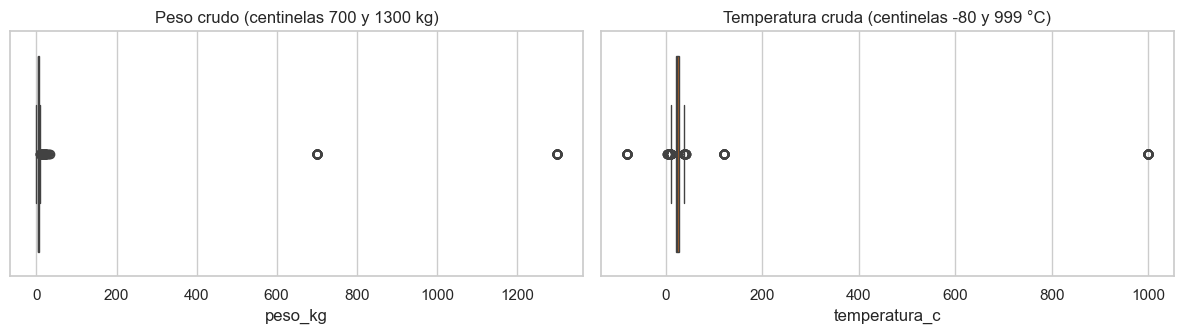

In [7]:
peso_ok = p.drop_duplicates()['peso_kg'].where(lambda x: (x > 0) & (x <= 100))
temp_ok = s['temperatura_c'].where(lambda x: x.between(-5, 45))
gigo1 = pd.DataFrame({
    'Estadística': ['Peso medio por pedido (kg)', 'Desv. estándar del peso (kg)', 'Temperatura media (°C)', 'Desv. estándar de la temperatura (°C)'],
    'Con datos crudos': [p['peso_kg'].mean(), p['peso_kg'].std(), s['temperatura_c'].mean(), s['temperatura_c'].std()],
    'Con datos corregidos': [peso_ok.mean(), peso_ok.std(), temp_ok.mean(), temp_ok.std()]}).round(2)
gigo1['Distorsión (%)'] = (100*(gigo1['Con datos crudos']/gigo1['Con datos corregidos'] - 1)).round(1)
display(gigo1)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
sns.boxplot(x=p['peso_kg'], ax=ax[0], color='#d95f02'); ax[0].set_title('Peso crudo (centinelas 700 y 1300 kg)')
sns.boxplot(x=s['temperatura_c'], ax=ax[1], color='#d95f02'); ax[1].set_title('Temperatura cruda (centinelas -80 y 999 °C)')
plt.tight_layout(); plt.show()

**Interpretación:** unos pocos centinelas (700, 1300, 999, -80) multiplican la media y la desviación estándar. Un modelo que escale o aprenda con esos valores recibiría una variable dominada por el ruido. El segundo ejemplo GIGO (impacto sobre las *predicciones*) se presenta en la sección 9, una vez construidos los modelos.

## 3. Tipos de variables
Clasificación de **todas** las variables según el diccionario de datos y lo observado. *Rol*: ID = identificador (llave, no medida), Predictor, Objetivo, Posterior (se conoce después de entregar → riesgo de fuga) o Metadato.

In [8]:
T = lambda archivo, var, clase, subtipo, rol, disp, desc: dict(archivo=archivo, variable=var, clase=clase, subtipo=subtipo, rol=rol, disponible_al_crear_pedido=disp, descripcion=desc)
tipos = pd.DataFrame([
 T('pedidos','pedido_id','Identificador','—','ID','Sí','Llave del pedido'),
 T('pedidos','cliente_id','Identificador','—','ID','Sí','Llave hacia clientes'),
 T('pedidos','zona_id','Identificador','—','ID','Sí','Llave hacia el catálogo de zonas'),
 T('pedidos','fecha_pedido','Fecha/hora','—','Predictor (derivado)','Sí','Momento de creación del pedido'),
 T('pedidos','tipo_servicio','Categórica','Nominal','Predictor','Sí','Estándar / Exprés'),
 T('pedidos','prioridad','Categórica','Ordinal (Baja<Media<Alta)','Predictor','Sí','Prioridad del pedido'),
 T('pedidos','distancia_km','Numérica','Continua','Predictor','Sí','Distancia de la entrega'),
 T('pedidos','numero_paquetes','Numérica','Discreta','Predictor','Sí','Paquetes del pedido'),
 T('pedidos','peso_kg','Numérica','Continua','Predictor','Sí','Peso total'),
 T('pedidos','tiempo_prometido_min','Numérica','Continua','Predictor','Sí','Tiempo prometido al cliente'),
 T('pedidos','tiempo_real_min','Numérica','Continua','Objetivo (regresión)','No','Tiempo real de entrega'),
 T('pedidos','entrega_tardia','Categórica','Binaria','Objetivo (clasificación)','No','1 si real - prometido > 5 min'),
 T('pedidos','fecha_entrega','Fecha/hora','—','Posterior','No','Momento de entrega'),
 T('pedidos','costo_final_mxn','Numérica','Continua','Posterior','No','Costo final cobrado'),
 T('pedidos','estado_entrega','Categórica','Nominal (binaria)','Posterior','No','A tiempo / Tarde'),
 T('pedidos','origen_registro','Categórica','Nominal','Metadato','Sí','Sistema que registró el pedido (ERP/SQL)'),
 T('sensores','lectura_id','Identificador','—','ID','—','Llave de la lectura (pedido + _0/_1)'),
 T('sensores','fecha_lectura','Fecha/hora','—','Metadato','—','Instante de la lectura'),
 T('sensores','temperatura_c','Numérica','Continua','Predictor','Sí (lectura _0)','Temperatura ambiente'),
 T('sensores','indice_trafico','Numérica','Continua','Predictor','Sí (lectura _0)','Índice de tráfico 0–100'),
 T('sensores','humedad_pct','Numérica','Continua','Predictor','Sí (lectura _0)','Humedad relativa'),
 T('sensores','lluvia_detectada','Categórica','Binaria','Predictor','Sí (lectura _0)','1 si llueve'),
 T('sensores','dispositivo_id','Categórica','Nominal (alta cardinalidad)','ID / Metadato','—','Sensor que midió'),
 T('clientes','tipo_cliente','Categórica','Nominal','Predictor','Sí','Nuevo / Recurrente / Empresa'),
 T('clientes','antiguedad_meses','Numérica','Discreta','Predictor','Sí','Meses como cliente'),
 T('clientes','satisfaccion_previa','Categórica','Ordinal (1–5)','Predictor','Sí','Satisfacción histórica'),
 T('clientes','canal_registro','Categórica','Nominal','Predictor','Sí','App / Tienda / Web'),
 T('zonas','zona','Categórica','Nominal','Predictor (redundante)','Sí','Nombre de la zona'),
 T('zonas','distancia_centro_km','Numérica','Continua','Predictor','Sí','Distancia de la zona al centro'),
 T('zonas','factor_trafico_historico','Numérica','Continua','Predictor','Sí','Factor histórico de tráfico'),
 T('zonas','ultima_actualizacion','Fecha/hora','—','Metadato','—','Última actualización del catálogo'),
 T('encuestas','puntuacion_entrega','Categórica','Ordinal (1–5)','Posterior','No','Calificación postentrega'),
 T('encuestas','recomendaria','Categórica','Nominal (binaria)','Posterior','No','Si / No'),
 T('encuestas','comentario','Texto','—','Posterior','No','Comentario libre'),
 T('encuestas','fecha_encuesta','Fecha/hora','—','Posterior','No','Fecha de la encuesta'),
])
display(tipos)
display(tipos.groupby(['clase', 'subtipo']).size().rename('n_variables').to_frame())

,archivo,variable,clase,subtipo,rol,disponible_al_crear_pedido,descripcion
0,pedidos,pedido_id,Identificador,—,ID,Sí,Llave del pedido
1,pedidos,cliente_id,Identificador,—,ID,Sí,Llave hacia clientes
2,pedidos,zona_id,Identificador,—,ID,Sí,Llave hacia el catálogo de zonas
3,pedidos,fecha_pedido,Fecha/hora,—,Predictor (derivado),Sí,Momento de creación del pedido
4,pedidos,tipo_servicio,Categórica,Nominal,Predictor,Sí,Estándar / Exprés
5,pedidos,prioridad,Categórica,Ordinal (Baja<Media<Alta),Predictor,Sí,Prioridad del pedido
6,pedidos,distancia_km,Numérica,Continua,Predictor,Sí,Distancia de la entrega
7,pedidos,numero_paquetes,Numérica,Discreta,Predictor,Sí,Paquetes del pedido
8,pedidos,peso_kg,Numérica,Continua,Predictor,Sí,Peso total
9,pedidos,tiempo_prometido_min,Numérica,Continua,Predictor,Sí,Tiempo prometido al cliente


n_variables
clase         subtipo                                 
Categórica    Binaria                                2
              Nominal                                5
              Nominal (alta cardinalidad)            1
              Nominal (binaria)                      2
              Ordinal (1–5)                          2
              Ordinal (Baja<Media<Alta)              1
Fecha/hora    —                                      5
Identificador —                                      4
Numérica      Continua                              10
              Discreta                               2
Texto         —                                      1

## 4. Integración de datos
**Granularidad de cada fuente**

| Fuente | Una fila representa | Llave | Relación con pedidos |
|---|---|---|---|
| pedidos | un pedido | `pedido_id` | — (tabla base, **1 fila por pedido**) |
| sensores | una lectura (2 por pedido) | `lectura_id` / `pedido_id` | **1 : N** → hay que pasarla a 1 fila por pedido |
| clientes | un cliente | `cliente_id` | N : 1 |
| zonas | una zona | `zona_id` | N : 1 |
| encuestas | una encuesta | `pedido_id` | 1 : 1 |

**Cómo se evita multiplicar los pedidos:** si se uniera `pedidos` con `sensores` directamente por `pedido_id`, cada pedido aparecería dos veces (una por lectura). Para evitarlo, (1) se eliminan primero solo las filas **idénticas** en todas sus columnas, (2) las lecturas se pasan a **formato ancho** (una columna por lectura: `_l0` y `_l1`, según el sufijo de `lectura_id`) y (3) cada unión se valida con `validate=` para que falle si la cardinalidad no es la esperada.

In [9]:
# 4.1 Eliminación de duplicados exactos (filas idénticas en TODAS las columnas = mismo registro cargado dos veces)
def sin_duplicados(df, nombre, llave):
    n0 = len(df); d = df.drop_duplicates().copy()
    log('Unicidad', nombre, llave, 'Filas idénticas repetidas', 'drop_duplicates() (se conserva la primera)', n0-len(d),
        f'{n0:,} filas', f'{len(d):,} filas', 'Las filas son idénticas en todas las columnas: no hay información distinta que perder')
    assert d[llave].is_unique, f'{nombre}: quedan llaves repetidas con valores distintos'
    print(f'{nombre:10s}: {n0:>6,} -> {len(d):>6,}  (eliminadas {n0-len(d):,}; llave {llave} única)')
    return d

pedidos   = sin_duplicados(pedidos_raw, 'pedidos', 'pedido_id')
clientes  = sin_duplicados(clientes_raw, 'clientes', 'cliente_id')
encuestas = sin_duplicados(encuestas_raw, 'encuestas', 'pedido_id')
zonas     = zonas_raw.copy()
sensores  = sensores_raw.drop_duplicates().copy()
n_dup_s   = len(sensores_raw) - len(sensores)
log('Unicidad', 'sensores', 'lectura_id', 'Lecturas idénticas repetidas', 'drop_duplicates()', n_dup_s,
    f'{len(sensores_raw):,} filas', f'{len(sensores):,} filas', 'Filas idénticas en todas las columnas')
assert sensores['lectura_id'].is_unique
print(f'sensores  : {len(sensores_raw):>6,} -> {len(sensores):>6,}  (eliminadas {n_dup_s:,})')

pedidos   : 12,220 -> 12,000  (eliminadas 220; llave pedido_id única)
clientes  :  2,580 ->  2,500  (eliminadas 80; llave cliente_id única)
encuestas : 12,140 -> 12,000  (eliminadas 140; llave pedido_id única)
sensores  : 24,280 -> 24,000  (eliminadas 280)


In [10]:
# 4.2 Sensores: de 2 filas por pedido a 1 fila por pedido (formato ancho)
sensores['orden_lectura'] = sensores['lectura_id'].str.split('_').str[-1]
print('Lecturas por pedido:', sensores.groupby('pedido_id').size().value_counts().to_dict())

# La lectura _0 coincide con el instante del pedido; la _1 es posterior. Se comprueba con las fechas:
chk = sensores.merge(pedidos[['pedido_id', 'fecha_pedido']], on='pedido_id')
chk['fp'] = pd.to_datetime(chk['fecha_pedido'], format='%Y-%m-%d %H:%M', errors='coerce')
chk['min_desde_pedido'] = (pd.to_datetime(chk['fecha_lectura']) - chk['fp']).dt.total_seconds()/60
print('Minutos entre pedido y lectura, por orden de lectura:')
display(chk.groupby('orden_lectura')['min_desde_pedido'].describe().round(2))

cols_s = ['fecha_lectura', 'temperatura_c', 'indice_trafico', 'humedad_pct', 'lluvia_detectada', 'dispositivo_id']
l0 = sensores[sensores['orden_lectura'] == '0'][['pedido_id'] + cols_s].rename(columns={c_: c_ + '_l0' for c_ in cols_s})
l1 = sensores[sensores['orden_lectura'] == '1'][['pedido_id'] + cols_s].rename(columns={c_: c_ + '_l1' for c_ in cols_s})
sensores_wide = l0.merge(l1, on='pedido_id', how='outer', validate='one_to_one')
print('sensores_wide:', sensores_wide.shape, '| pedidos únicos:', sensores_wide['pedido_id'].nunique())

Lecturas por pedido: {2: 12000}
Minutos entre pedido y lectura, por orden de lectura:


,count,mean,std,min,25%,50%,75%,max
orden_lectura,,,,,,,,
0,11810.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,11810.0,5.0,0.0,5.0,5.0,5.0,5.0,5.0


sensores_wide: (12000, 13) | pedidos únicos: 12000


> **Decisión importante:** la lectura `_0` se registra en el mismo instante en que se crea el pedido, mientras que la `_1` se toma unos minutos **después**. Como la predicción debe hacerse al crear el pedido, para el modelado se usará **solo la lectura `_0`**; la `_1` se conserva en el dataset integrado pero se marca como no disponible al momento de la predicción.

In [11]:
# 4.3 Uniones (todas LEFT desde pedidos, validando cardinalidad)
df_int = (pedidos
          .merge(sensores_wide, on='pedido_id', how='left', validate='one_to_one')
          .merge(clientes, on='cliente_id', how='left', validate='many_to_one')
          .merge(zonas, on='zona_id', how='left', validate='many_to_one')
          .merge(encuestas, on='pedido_id', how='left', validate='one_to_one'))

assert len(df_int) == pedidos['pedido_id'].nunique() == len(pedidos), 'La integración multiplicó o perdió pedidos'
print(f'Dataset integrado: {df_int.shape[0]:,} pedidos x {df_int.shape[1]} columnas  (1 fila por pedido)')

huerfanos = pd.Series({
    'pedidos sin cliente en clientes': int(df_int['tipo_cliente'].isna().sum()),
    'pedidos con zona fuera del catálogo': int(df_int['zona'].isna().sum()),
    'pedidos sin lecturas de sensor': int(df_int['fecha_lectura_l0'].isna().sum()),
    'pedidos sin encuesta': int(df_int['recomendaria'].isna().sum())})
print('\nRegistros sin coincidencia (se conservan con LEFT JOIN, no se eliminan):'); display(huerfanos.to_frame('n'))
log('Integración', 'todas', 'pedido_id', 'Unión de 5 fuentes con granularidades distintas',
    'Sensores en formato ancho + LEFT JOIN con validate=', 0, f'{len(pedidos):,} pedidos', f'{len(df_int):,} filas',
    'Se conserva 1 fila por pedido; los huérfanos (C9999, Z99) no se borran, se etiquetan como Desconocido')
df_int.head(3)

Dataset integrado: 12,000 pedidos x 40 columnas  (1 fila por pedido)

Registros sin coincidencia (se conservan con LEFT JOIN, no se eliminan):


,n
pedidos sin cliente en clientes,170
pedidos con zona fuera del catálogo,160
pedidos sin lecturas de sensor,0
pedidos sin encuesta,0


,pedido_id,cliente_id,zona_id,fecha_pedido,tipo_servicio,prioridad,distancia_km,numero_paquetes,peso_kg,tiempo_prometido_min,tiempo_real_min,entrega_tardia,fecha_entrega,costo_final_mxn,estado_entrega,origen_registro,fecha_lectura_l0,temperatura_c_l0,indice_trafico_l0,humedad_pct_l0,lluvia_detectada_l0,dispositivo_id_l0,fecha_lectura_l1,temperatura_c_l1,indice_trafico_l1,humedad_pct_l1,lluvia_detectada_l1,dispositivo_id_l1,tipo_cliente,antiguedad_meses,satisfaccion_previa,canal_registro,zona,distancia_centro_km,factor_trafico_historico,ultima_actualizacion,puntuacion_entrega,recomendaria,comentario,fecha_encuesta
0,P00001,C1180,Z06,2026-07-14 12:03,Exprés,Alta,24.99,6,3.72,92.8,101.0,1,2026-07-14 13:44,337.91,Tarde,SQL,2026-07-14 12:03:00,17.627256,53.0,80.8,1,SEN-06-02,2026-07-14 12:08:00,16.921948,49.3,58.3,1,SEN-06-04,Recurrente,32.0,4.0,App,Aeropuerto,19.0,1.35,2018-02-01,3.0,No,Buen servicio,2026-07-18
1,P00002,C1435,Z03,2026-09-10 12:05,Estándar,Media,7.27,8,5.50,37.3,54.9,1,2026-09-10 12:59,194.43,Tarde,SQL,2026-09-10 12:05:00,21.028689,57.9,27.2,0,SEN-03-07,2026-09-10 12:10:00,21.231011,alto,60.4,0,SEN-03-08,Recurrente,24.0,3.0,Web,Centro,6.0,1.30,2026-09-30,3.0,No,Todo bien,2026-09-14
2,P00003,C1714,Z05,2026-10-20 11:26,Exprés,Alta,12.06,8,700.00,49.2,42.1,0,2026-10-20 12:08,217.54,A tiempo,ERP,2026-10-20 11:26:00,21.612193,28.9,56.0,1,SEN-05-06,2026-10-20 11:31:00,20.928018,29.6,78.3,1,SEN-05-05,Recurrente,41.0,2.0,Tienda,Poniente,11.0,1.12,2026-09-30,5.0,Si,Buen servicio,2026-10-23


## 5. Limpieza de datos
Se trabaja sobre una copia del dataset integrado (`df`). Orden de las decisiones:

1. **Consistencia de formatos** (categorías y números en texto).
2. **Fechas** (inválidas, faltantes) — se reparan con evidencia de los propios datos.
3. **Validez**: los valores *imposibles* se convierten a `NaN` (no se borra el registro).
4. **Valores atípicos plausibles**: se revisan y se conservan si tienen explicación.
5. **Faltantes**: se documentan; la imputación estadística se aprende **solo con entrenamiento** (sección 7) para no filtrar información del conjunto de prueba.

Todos los cambios quedan en la **bitácora** (`bitacora`) con valores antes/después. Ninguna regla de esta sección aprende parámetros de los datos, por lo que puede aplicarse a todo el dataset sin riesgo de fuga.

In [12]:
df = df_int.copy()
def comparar(antes, despues, nombre):
    t = pd.concat([antes.rename('antes'), despues.rename('después')], axis=1).fillna(0).astype(int)
    t.index.name = nombre; return t

# 5.1 Categorías: prioridad (ordinal) y tipo_cliente (nominal)
a = df['prioridad'].value_counts(dropna=False)
df['prioridad'] = df['prioridad'].str.strip().str.capitalize().replace({'Medio': 'Media'})
display(comparar(a, df['prioridad'].value_counts(dropna=False), 'prioridad'))
log('Consistencia', 'pedidos', 'prioridad', 'Variantes de escritura (ALTA, media, " BAJA ", Medio)', 'strip + capitalize + Medio→Media',
    int(a[a.index.notna() & ~a.index.isin(['Baja', 'Media', 'Alta'])].sum()), dict(a), dict(df['prioridad'].value_counts(dropna=False)),
    'Son la misma categoría escrita distinto; se normaliza sin perder registros. Los vacíos (NaN) se imputarán con la moda de entrenamiento.')

a = df['tipo_cliente'].value_counts(dropna=False)
df['tipo_cliente'] = (df['tipo_cliente'].str.strip().str.lower().replace({'recurr.': 'recurrente'})
                      .str.capitalize().fillna('Desconocido'))
display(comparar(a, df['tipo_cliente'].value_counts(dropna=False), 'tipo_cliente'))
log('Consistencia', 'clientes', 'tipo_cliente', 'Variantes de escritura y clientes sin ficha (C9999)', 'Normalización + categoría "Desconocido"',
    int(a.drop(['Recurrente', 'Nuevo', 'Empresa'], errors='ignore').sum()), dict(a), dict(df['tipo_cliente'].value_counts(dropna=False)),
    'Los pedidos de clientes sin ficha no se eliminan: "Desconocido" es información válida (el cliente no está registrado)')

,antes,después
prioridad,,
Media,6495,6580
Alta,2947,3034
Baja,2308,2351
ALTA,48,0
Medio,44,0
BAJA,43,0
media,41,0
alta,39,0
NaN,35,35


,antes,después
tipo_cliente,,
Recurrente,6430,6640
Nuevo,2670,2832
Empresa,2022,2358
empresa,219,0
Recurr.,210,0
NaN,170,0
nuevo,162,0
EMPRESA,117,0
Desconocido,0,170


In [13]:
# 5.2 Números guardados como texto: distancia_km e índices de tráfico
def a_numero(serie):
    t = (serie.astype(str).str.strip().str.lower().str.replace('km', '', regex=False)
         .str.replace(',', '.', regex=False).str.strip())
    return pd.to_numeric(t, errors='coerce')

for col in ['distancia_km', 'indice_trafico_l0', 'indice_trafico_l1']:
    antes_nulos = int(df[col].isna().sum()); crudo = df[col].copy()
    df[col] = a_numero(df[col])
    recuperados = int((crudo.notna() & df[col].notna() & pd.to_numeric(crudo, errors='coerce').isna()).sum())
    texto_no_num = int((crudo.notna() & df[col].isna()).sum())
    print(f'{col}: nulos {antes_nulos} -> {int(df[col].isna().sum())} | recuperados desde formato texto: {recuperados} | texto no numérico → NaN: {texto_no_num}')
    log('Consistencia', 'integrado', col, "Texto en columna numérica ('12,5', '8 km', 'alto', 'n/d')", 'Conversión a float (coma decimal, sufijo km); no numérico → NaN',
        recuperados + texto_no_num, f'nulos={antes_nulos}', f'nulos={int(df[col].isna().sum())}',
        "'12,5' y '8 km' son valores válidos mal formateados (se recuperan); 'alto'/'n/d' no tienen valor numérico (NaN, no se inventa)")
df[['distancia_km', 'indice_trafico_l0', 'indice_trafico_l1']].describe().round(2)

distancia_km: nulos 297 -> 382 | recuperados desde formato texto: 185 | texto no numérico → NaN: 85
indice_trafico_l0: nulos 308 -> 376 | recuperados desde formato texto: 0 | texto no numérico → NaN: 68
indice_trafico_l1: nulos 284 -> 356 | recuperados desde formato texto: 0 | texto no numérico → NaN: 72


,distancia_km,indice_trafico_l0,indice_trafico_l1
count,11618.00,11624.00,11644.00
mean,13.79,55.31,55.14
std,5.79,20.34,20.41
min,1.00,-10.00,-10.00
25%,9.45,40.80,40.30
50%,13.57,54.60,54.40
75%,18.00,69.90,69.80
max,33.08,108.30,109.40


In [14]:
# 5.3 Fechas: formato, calendario inválido y faltantes
fp = pd.to_datetime(df['fecha_pedido'], format='%Y-%m-%d %H:%M', errors='coerce')
fe = pd.to_datetime(df['fecha_entrega'], format='%Y-%m-%d %H:%M', errors='coerce')
invalidas = df.loc[fp.isna(), 'fecha_pedido']
print('Valores de fecha_pedido no interpretables:', invalidas.value_counts(dropna=False).to_dict())

# Evidencia: en los registros válidos, fecha_entrega - tiempo_real_min = fecha_pedido (±1 min)
rec = (fe - pd.to_timedelta(df['tiempo_real_min'], unit='m')).dt.round('min')
ok = fp.notna()
dif = (rec[ok] - fp[ok]).dt.total_seconds().abs()/60
print(f'Reconstrucción vs fecha real en {ok.sum():,} registros válidos: coincide (≤1 min) en {(dif <= 1).mean():.1%}')

df['fecha_pedido_reconstruida'] = fp.isna().astype(int)
df['fecha_pedido'] = fp.fillna(rec)
df['fecha_entrega'] = fe
for col in ['fecha_lectura_l0', 'fecha_lectura_l1', 'fecha_encuesta']:
    df[col] = pd.to_datetime(df[col], errors='coerce')
assert df['fecha_pedido'].notna().all()
log('Fechas', 'pedidos', 'fecha_pedido', "Fechas inválidas ('31/02/2026', '2026/99/12') o faltantes ('s/f')", 'Reconstrucción: fecha_entrega - tiempo_real_min (flag fecha_pedido_reconstruida=1)',
    int(df['fecha_pedido_reconstruida'].sum()), f'{int(fp.isna().sum())} no interpretables', '0 nulos',
    'La relación fecha_entrega - tiempo_real = fecha_pedido se cumple en los registros válidos; se usa SOLO para reparar la fecha (no como variable predictora)')

# Revisión de coherencia temporal
print('\nPeriodo de pedidos:', df['fecha_pedido'].min(), '→', df['fecha_pedido'].max())
print('Entregas anteriores al pedido:', int((df['fecha_entrega'] < df['fecha_pedido']).sum()))
print('Encuestas anteriores a la entrega:', int((df['fecha_encuesta'] < df['fecha_entrega'].dt.normalize()).sum()))
print('Pedidos por mes:'); display(df['fecha_pedido'].dt.to_period('M').value_counts().sort_index().to_frame('pedidos'))

Valores de fecha_pedido no interpretables: {'31/02/2026': 74, 's/f': 61, '2026/99/12': 55}
Reconstrucción vs fecha real en 11,810 registros válidos: coincide (≤1 min) en 100.0%

Periodo de pedidos: 2026-07-01 06:17:00 → 2026-10-28 19:46:00
Entregas anteriores al pedido: 0
Encuestas anteriores a la entrega: 0
Pedidos por mes:


,pedidos
fecha_pedido,
2026-07,3057
2026-08,3146
2026-09,3034
2026-10,2763


In [15]:
# 5.4 Validez: valores imposibles -> NaN (el registro se conserva)
for col in ['numero_paquetes', 'peso_kg', 'antiguedad_meses', 'puntuacion_entrega', 'temperatura_c_l0', 'temperatura_c_l1',
            'humedad_pct_l0', 'humedad_pct_l1', 'indice_trafico_l0', 'indice_trafico_l1']:
    df[col] = df[col].astype(float)

def invalidar(col, mask, regla):
    mask = mask.fillna(False); n = int(mask.sum())
    antes = f'media={df[col].mean():.2f} | mín={df[col].min():.2f} | máx={df[col].max():.2f}'
    df.loc[mask, col] = np.nan
    despues = f'media={df[col].mean():.2f} | mín={df[col].min():.2f} | máx={df[col].max():.2f}'
    log('Validez', 'integrado', col, regla, 'Valor → NaN (registro conservado)', n, antes, despues,
        'Valor imposible en el dominio del negocio/físico; se trata como faltante e imputa sin usar datos de prueba')
    return dict(variable=col, regla=regla, registros=n, pct=round(100*n/len(df), 2), antes=antes, despues=despues)

reglas = [
    invalidar('numero_paquetes', (df['numero_paquetes'] <= 0) | (df['numero_paquetes'] > 50), 'paquetes ≤ 0 o centinela 150 (válidos: 1–8)'),
    invalidar('peso_kg', (df['peso_kg'] <= 0) | (df['peso_kg'] > 100), 'peso ≤ 0 o > 100 kg (centinelas 700 / 1300)'),
    invalidar('antiguedad_meses', df['antiguedad_meses'] < 0, 'antigüedad negativa'),
    invalidar('puntuacion_entrega', ~df['puntuacion_entrega'].between(1, 5), 'puntuación fuera de escala 1–5'),
]
for l in ['l0', 'l1']:
    reglas += [
        invalidar(f'temperatura_c_{l}', ~df[f'temperatura_c_{l}'].between(-5, 45), 'temperatura fuera de [-5, 45] °C (centinelas -80 / 999)'),
        invalidar(f'humedad_pct_{l}', ~df[f'humedad_pct_{l}'].between(0, 100), 'humedad fuera de [0, 100] %'),
        invalidar(f'indice_trafico_{l}', ~df[f'indice_trafico_{l}'].between(0, 100), 'índice de tráfico fuera de [0, 100]'),
    ]
pd.DataFrame(reglas)

,variable,regla,registros,pct,antes,despues
0,numero_paquetes,paquetes ≤ 0 o centinela 150 (válidos: 1–8),160,1.33,media=5.11 | mín=-2.00 | máx=150.00,media=4.52 | mín=1.00 | máx=8.00
1,peso_kg,peso ≤ 0 o > 100 kg (centinelas 700 / 1300),210,1.75,media=16.46 | mín=-1.00 | máx=1300.00,media=4.46 | mín=0.58 | máx=33.27
2,antiguedad_meses,antigüedad negativa,352,2.93,media=24.48 | mín=-2.00 | máx=50.00,media=25.29 | mín=0.00 | máx=50.00
3,puntuacion_entrega,puntuación fuera de escala 1–5,893,7.44,media=4.06 | mín=1.00 | máx=7.00,media=4.02 | mín=1.00 | máx=5.00
4,temperatura_c_l0,"temperatura fuera de [-5, 45] °C (centinelas -80 / 999)",137,1.14,media=27.71 | mín=-80.00 | máx=999.00,media=24.00 | mín=3.36 | máx=41.99
5,humedad_pct_l0,"humedad fuera de [0, 100] %",154,1.28,media=57.48 | mín=-2.00 | máx=140.00,media=57.30 | mín=16.00 | máx=98.00
6,indice_trafico_l0,"índice de tráfico fuera de [0, 100]",523,4.36,media=55.31 | mín=-10.00 | máx=108.30,media=54.95 | mín=0.10 | máx=100.00
7,temperatura_c_l1,"temperatura fuera de [-5, 45] °C (centinelas -80 / 999)",133,1.11,media=27.59 | mín=-80.00 | máx=999.00,media=24.00 | mín=2.72 | máx=42.05
8,humedad_pct_l1,"humedad fuera de [0, 100] %",146,1.22,media=57.82 | mín=-2.00 | máx=140.00,media=57.70 | mín=16.00 | máx=98.00
9,indice_trafico_l1,"índice de tráfico fuera de [0, 100]",520,4.33,media=55.14 | mín=-10.00 | máx=109.40,media=54.80 | mín=1.70 | máx=100.00


In [16]:
# 5.5 Llaves huérfanas: zona fuera de catálogo (Z99) y dispositivo sin identificar
df['zona_fuera_catalogo'] = df['zona'].isna().astype(int)
n_z = int(df['zona_fuera_catalogo'].sum())
df['zona'] = df['zona'].fillna('Desconocida')
log('Validez', 'pedidos/zonas', 'zona_id / zona', 'zona_id Z99 inexistente en el catálogo', 'zona="Desconocida", flag zona_fuera_catalogo=1; sus atributos de zona quedan NaN (imputados en entrenamiento)',
    n_z, f'{n_z} sin zona', f'{n_z} con zona "Desconocida"', 'No se descartan: son pedidos reales; el flag permite al modelo y a la auditoría identificarlos')
for l in ['l0', 'l1']:
    df[f'dispositivo_id_{l}'] = df[f'dispositivo_id_{l}'].fillna('Desconocido')
print(f'Pedidos con zona fuera de catálogo: {n_z} ({100*n_z/len(df):.2f}%)')

# Actualidad del catálogo: la zona Z06 no se actualiza desde 2018
print('\nCatálogo de zonas (nota la fecha de Z06):'); display(zonas)
n_z06 = int((df['zona_id'] == 'Z06').sum())
log('Actualidad', 'zonas', 'factor_trafico_historico', 'Z06 (Aeropuerto) sin actualizar desde 2018', 'Se conserva y se documenta como limitación', n_z06,
    '2018-02-01', '2018-02-01', 'No hay valor más reciente con el cual reemplazarlo; se señala el riesgo en las conclusiones')

cl = clima_raw.copy()
cl['fecha'] = pd.to_datetime(cl['fecha'], format='%d/%m/%Y', errors='coerce')
cl = cl.dropna(subset=['fecha']).drop_duplicates(['fecha', 'zona_id'])
cl['alerta_climatica'] = cl['alerta_climatica'].astype(str).str.strip().str.capitalize()

# Evita sufijos _x/_y cuando esta celda se ejecuta más de una vez.
climas_previos = [c_ for c_ in df.columns if c_ == 'alerta_climatica' or c_.startswith('alerta_climatica_')]
df = df.drop(columns=climas_previos, errors='ignore')
df['_dia'] = df['fecha_pedido'].dt.normalize()
df = df.merge(
    cl[['fecha', 'zona_id', 'alerta_climatica']].rename(columns={'alerta_climatica': '_alerta_climatica'}),
    left_on=['_dia', 'zona_id'], right_on=['fecha', 'zona_id'],
    how='left', validate='many_to_one'
).drop(columns=['fecha', '_dia'])
df['alerta_climatica'] = df.pop('_alerta_climatica').fillna('Sin reporte')
assert len(df) == len(df_int)
print('Clima integrado por fecha + zona_id:', df['alerta_climatica'].value_counts().to_dict())

Pedidos con zona fuera de catálogo: 160 (1.33%)

Catálogo de zonas (nota la fecha de Z06):


,zona_id,zona,distancia_centro_km,factor_trafico_historico,ultima_actualizacion
0,Z01,Norte,8,1.05,2026-09-30
1,Z02,Sur,13,1.15,2026-09-30
2,Z03,Centro,6,1.30,2026-09-30
3,Z04,Oriente,15,1.25,2026-09-30
4,Z05,Poniente,11,1.12,2026-09-30
5,Z06,Aeropuerto,19,1.35,2018-02-01


Clima integrado por fecha + zona_id: {'Sin alerta': 5711, 'Lluvia': 3088, 'Tormenta': 3041, 'Sin reporte': 160}


,variable,validos,Q1,Q3,lim_inf,lim_sup,atipicos_1_5IQR,pct,extremos_3IQR
0,distancia_km,11618,9.45,18.00,-3.38,30.83,5,0.04,0
1,numero_paquetes,11840,2.00,7.00,-5.50,14.50,0,0.00,0
2,peso_kg,11554,2.66,5.56,-1.69,9.91,477,4.13,93
3,tiempo_prometido_min,12000,43.70,69.30,5.30,107.70,5,0.04,0
4,tiempo_real_min,12000,42.18,72.00,-2.56,116.74,23,0.19,0
5,costo_final_mxn,12000,171.00,253.34,47.49,376.85,10,0.08,0
6,temperatura_c_l0,11863,20.62,27.43,10.41,37.64,75,0.63,0
7,indice_trafico_l0,11477,40.70,69.50,-2.50,112.70,0,0.00,0
8,humedad_pct_l0,11846,47.20,67.30,17.05,97.45,65,0.55,0
9,antiguedad_meses,11478,12.00,38.00,-27.00,77.00,0,0.00,0



Los 5 pedidos más largos: ¿hay una explicación operativa?


,pedido_id,distancia_km,tiempo_prometido_min,tiempo_real_min,indice_trafico_l0,lluvia_detectada_l0,zona
11094,P11095,NaN,98.2,131.6,50.2,1,Aeropuerto
9662,P09663,23.07,88.8,130.6,83.5,1,Aeropuerto
9539,P09540,27.30,90.0,130.3,92.0,1,Aeropuerto
5313,P05314,22.16,88.0,126.9,94.3,1,Oriente
4748,P04749,32.01,106.6,126.0,39.5,0,Aeropuerto


Correlación distancia_km vs tiempo_real_min: 0.787
Pedidos con peso entre 20 y 100 kg (conservados): 13


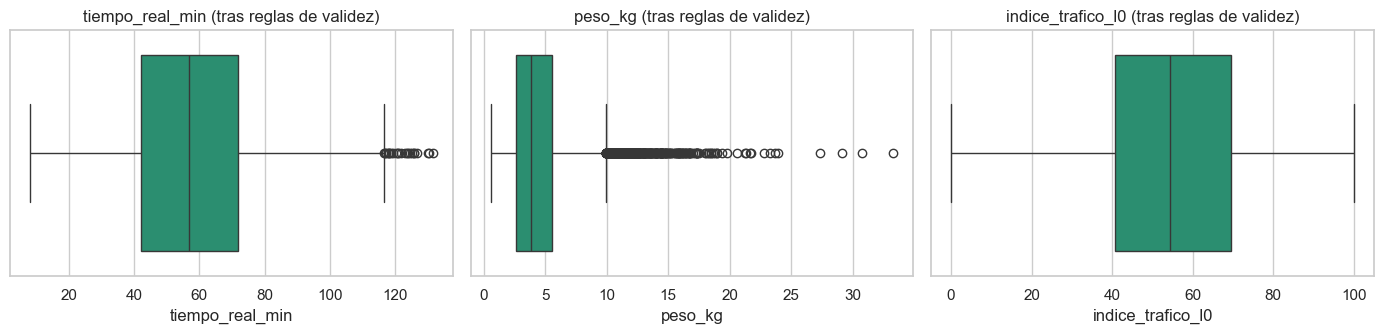

In [17]:
# 5.6 Valores atípicos: se revisan con IQR, pero NO se asume que todo extremo sea un error
cols_num = ['distancia_km', 'numero_paquetes', 'peso_kg', 'tiempo_prometido_min', 'tiempo_real_min', 'costo_final_mxn',
            'temperatura_c_l0', 'indice_trafico_l0', 'humedad_pct_l0', 'antiguedad_meses', 'factor_trafico_historico']
filas = []
for col in cols_num:
    x = df[col].dropna(); q1, q3 = x.quantile([.25, .75]); i = q3 - q1
    inf, sup = q1 - 1.5*i, q3 + 1.5*i
    n15 = int(((x < inf) | (x > sup)).sum()); n3 = int(((x < q1 - 3*i) | (x > q3 + 3*i)).sum())
    filas.append(dict(variable=col, validos=len(x), Q1=q1, Q3=q3, lim_inf=inf, lim_sup=sup, atipicos_1_5IQR=n15, pct=round(100*n15/len(x), 2), extremos_3IQR=n3))
tabla_atipicos = pd.DataFrame(filas).round(2); display(tabla_atipicos)

print('\nLos 5 pedidos más largos: ¿hay una explicación operativa?')
display(df.nlargest(5, 'tiempo_real_min')[['pedido_id', 'distancia_km', 'tiempo_prometido_min', 'tiempo_real_min', 'indice_trafico_l0', 'lluvia_detectada_l0', 'zona']])
print('Correlación distancia_km vs tiempo_real_min:', round(df['distancia_km'].corr(df['tiempo_real_min']), 3))
print('Pedidos con peso entre 20 y 100 kg (conservados):', int(df['peso_kg'].between(20, 100).sum()))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a_, col in zip(ax, ['tiempo_real_min', 'peso_kg', 'indice_trafico_l0']):
    sns.boxplot(x=df[col], ax=a_, color='#1b9e77'); a_.set_title(f'{col} (tras reglas de validez)')
plt.tight_layout(); plt.show()

log('Atípicos', 'integrado', 'tiempo_real_min, costo_final_mxn, peso_kg (20–100 kg)', 'Valores extremos por IQR', 'Se CONSERVAN sin modificar', int(tabla_atipicos['atipicos_1_5IQR'].sum()),
    'ver tabla_atipicos', 'sin cambios', 'Los tiempos largos se explican por distancia/tráfico/lluvia; son la señal que el modelo debe aprender. Los errores reales (centinelas) ya se trataron como inválidos.')

**Decisión sobre atípicos:** los valores *imposibles* (999 °C, 700 kg, 150 paquetes) ya se convirtieron a `NaN` por validez. Los que siguen siendo extremos según el IQR (por ejemplo, entregas de más de 100 minutos o pedidos de 20–33 kg) **son plausibles** y se conservan: eliminarlos haría que el modelo no aprendiera justo los casos de retraso que interesa detectar.

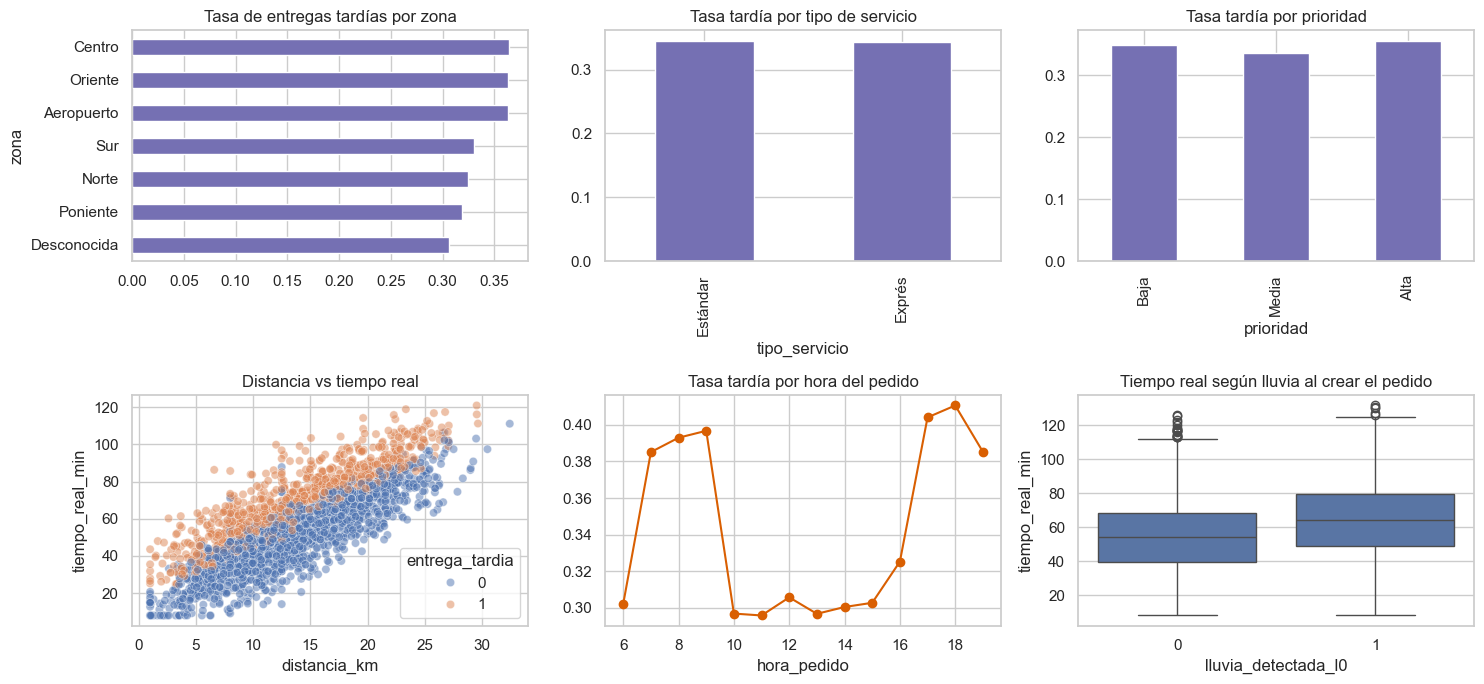

Tasa global de entregas tardías: 0.3435


In [18]:
# 5.7 Variables derivadas de la fecha del pedido (disponibles al crear el pedido)
df['hora_pedido'] = df['fecha_pedido'].dt.hour
df['dia_semana'] = df['fecha_pedido'].dt.dayofweek
df['es_fin_semana'] = (df['dia_semana'] >= 5).astype(int)
df['demora_min'] = df['tiempo_real_min'] - df['tiempo_prometido_min']   # SOLO descriptiva (posterior)

# Exploración rápida del fenómeno
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
df.groupby('zona')['entrega_tardia'].mean().sort_values().plot.barh(ax=ax[0, 0], color='#7570b3'); ax[0, 0].set_title('Tasa de entregas tardías por zona')
df.groupby('tipo_servicio')['entrega_tardia'].mean().plot.bar(ax=ax[0, 1], color='#7570b3'); ax[0, 1].set_title('Tasa tardía por tipo de servicio')
df.groupby('prioridad')['entrega_tardia'].mean().reindex(['Baja', 'Media', 'Alta']).plot.bar(ax=ax[0, 2], color='#7570b3'); ax[0, 2].set_title('Tasa tardía por prioridad')
sns.scatterplot(data=df.sample(2500, random_state=SEED), x='distancia_km', y='tiempo_real_min', hue='entrega_tardia', alpha=.5, ax=ax[1, 0]); ax[1, 0].set_title('Distancia vs tiempo real')
df.groupby('hora_pedido')['entrega_tardia'].mean().plot(marker='o', ax=ax[1, 1], color='#d95f02'); ax[1, 1].set_title('Tasa tardía por hora del pedido')
sns.boxplot(data=df, x='lluvia_detectada_l0', y='tiempo_real_min', ax=ax[1, 2]); ax[1, 2].set_title('Tiempo real según lluvia al crear el pedido')
plt.tight_layout(); plt.show()
print('Tasa global de entregas tardías:', round(df['entrega_tardia'].mean(), 4))

In [19]:
# 5.8 Faltantes que permanecen tras la limpieza (se imputan DENTRO del pipeline, aprendiendo solo del entrenamiento)
nulos = df.isna().sum(); nulos = nulos[nulos > 0]
estrategia = {
    'prioridad': 'moda (ordinal categórica)', 'distancia_km': 'mediana + indicador de faltante', 'peso_kg': 'mediana + indicador',
    'numero_paquetes': 'mediana + indicador', 'antiguedad_meses': 'mediana + indicador', 'satisfaccion_previa': 'mediana + indicador',
    'distancia_centro_km': 'mediana (solo zona Z99)', 'factor_trafico_historico': 'mediana (solo zona Z99)',
    'puntuacion_entrega': 'NO se imputa: variable posterior, no se usa en modelos', 'recomendaria': 'NO se imputa: posterior',
    'canal_registro': 'categoría "Desconocido" (cliente sin ficha, C9999)', 'ultima_actualizacion': 'NO se imputa: metadato del catálogo (zona Z99 sin registro)',
}
tabla_nulos = pd.DataFrame({'nulos': nulos, '% nulos': (100*nulos/len(df)).round(2)})
tabla_nulos['tratamiento'] = [estrategia.get(i, 'mediana + indicador (lectura de sensor)' if ('_l0' in i or '_l1' in i) else 'revisar') for i in tabla_nulos.index]
display(tabla_nulos)

,nulos,% nulos,tratamiento
prioridad,35,0.29,moda (ordinal categórica)
distancia_km,382,3.18,mediana + indicador de faltante
numero_paquetes,160,1.33,mediana + indicador
peso_kg,446,3.72,mediana + indicador
temperatura_c_l0,137,1.14,mediana + indicador (lectura de sensor)
indice_trafico_l0,523,4.36,mediana + indicador (lectura de sensor)
humedad_pct_l0,154,1.28,mediana + indicador (lectura de sensor)
temperatura_c_l1,133,1.11,mediana + indicador (lectura de sensor)
indice_trafico_l1,520,4.33,mediana + indicador (lectura de sensor)
humedad_pct_l1,146,1.22,mediana + indicador (lectura de sensor)


## 6. Selección de variables
**Población:** los 12,000 pedidos únicos del periodo julio–octubre de 2026 (todas las zonas, incluidas las que están fuera de catálogo).
**Criterio central:** una variable es válida solo si se conoce **al momento de crear el pedido**.

In [20]:
S = lambda v, d, m: dict(variable=v, decision=d, motivo=m)
seleccion = pd.DataFrame([
 S('pedido_id, cliente_id, zona_id', 'Descartar (ID)', 'Son llaves, no medidas: un modelo las memorizaría sin generalizar'),
 S('fecha_pedido', 'Transformar', 'Se reemplaza por hora_pedido y es_fin_semana (no se usa el sello de tiempo crudo)'),
 S('tipo_servicio, prioridad, distancia_km, numero_paquetes, peso_kg', 'USAR', 'Se conocen al registrar el pedido'),
 S('tiempo_prometido_min', 'USAR', 'Lo indica el enunciado: está disponible antes de la entrega'),
 S('temperatura_c_l0, indice_trafico_l0, humedad_pct_l0, lluvia_detectada_l0', 'USAR', 'Lectura tomada en el instante de creación del pedido (_0)'),
 S('*_l1 (segunda lectura de sensor)', 'Descartar (posible fuga)', 'Se toma minutos DESPUÉS de crear el pedido: no existe al momento de predecir'),
 S('dispositivo_id_l0, dispositivo_id_l1, fecha_lectura_*', 'Descartar (ID/metadato)', 'Identificador de dispositivo (alta cardinalidad) y sellos de tiempo, sin valor causal'),
 S('tipo_cliente, antiguedad_meses, satisfaccion_previa, canal_registro', 'USAR', 'Atributos históricos del cliente, previos al pedido'),
 S('distancia_centro_km, factor_trafico_historico', 'USAR', 'Atributos del catálogo de zonas (la zona de Z06 está desactualizada: ver actualidad)'),
 S('zona (nombre)', 'Descartar (redundante)', 'Cada zona tiene valores únicos de sus dos atributos numéricos: aporta la misma información'),
 S('zona_fuera_catalogo', 'USAR', 'Bandera de calidad (zona Z99) para que el modelo pueda tratar esos casos aparte'),
 S('origen_registro', 'Descartar (metadato)', 'Indica el sistema que guardó el dato, no una condición de la entrega; su uso induciría sesgos de captura'),
 S('tiempo_real_min', 'OBJETIVO (regresión) / FUGA para clasificación', 'Es el resultado observado; entrega_tardia se calcula a partir de él'),
 S('entrega_tardia', 'OBJETIVO (clasificación) / FUGA para regresión', 'Etiqueta: real - prometido > 5 min'),
 S('fecha_entrega, estado_entrega, costo_final_mxn', 'FUGA', 'Información posterior a la entrega; estado_entrega repite la etiqueta'),
 S('puntuacion_entrega, recomendaria, comentario, fecha_encuesta', 'FUGA', 'La encuesta se responde después de entregar'),
 S('demora_min', 'FUGA', 'Es tiempo_real_min - tiempo_prometido_min'),
 S('fecha_pedido_reconstruida', 'Descartar (calidad)', 'Bandera de auditoría, no una condición operativa'),
])
display(seleccion)

,variable,decision,motivo
0,"pedido_id, cliente_id, zona_id",Descartar (ID),"Son llaves, no medidas: un modelo las memorizaría sin ge..."
1,fecha_pedido,Transformar,Se reemplaza por hora_pedido y es_fin_semana (no se usa ...
2,"tipo_servicio, prioridad, distancia_km, numero_paquetes,...",USAR,Se conocen al registrar el pedido
3,tiempo_prometido_min,USAR,Lo indica el enunciado: está disponible antes de la entrega
4,"temperatura_c_l0, indice_trafico_l0, humedad_pct_l0, llu...",USAR,Lectura tomada en el instante de creación del pedido (_0)
5,*_l1 (segunda lectura de sensor),Descartar (posible fuga),Se toma minutos DESPUÉS de crear el pedido: no existe al...
6,"dispositivo_id_l0, dispositivo_id_l1, fecha_lectura_*",Descartar (ID/metadato),Identificador de dispositivo (alta cardinalidad) y sello...
7,"tipo_cliente, antiguedad_meses, satisfaccion_previa, can...",USAR,"Atributos históricos del cliente, previos al pedido"
8,"distancia_centro_km, factor_trafico_historico",USAR,Atributos del catálogo de zonas (la zona de Z06 está des...
9,zona (nombre),Descartar (redundante),Cada zona tiene valores únicos de sus dos atributos numé...


In [21]:
# Evidencia de fuga: ¿qué pasa si se usan las variables posteriores?
print('estado_entrega vs entrega_tardia:'); display(pd.crosstab(df['estado_entrega'], df['entrega_tardia']))
print('Correlación costo_final_mxn vs tiempo_real_min:', round(df['costo_final_mxn'].corr(df['tiempo_real_min']), 3))
print('Correlación demora_min vs entrega_tardia      :', round(df['demora_min'].corr(df['entrega_tardia']), 3))

num_demo = ['distancia_km', 'numero_paquetes', 'peso_kg', 'tiempo_prometido_min', 'indice_trafico_l0', 'temperatura_c_l0', 'humedad_pct_l0', 'lluvia_detectada_l0']
D = df[num_demo].fillna(-1); D_fuga = D.assign(tiempo_real_min=df['tiempo_real_min'], demora_min=df['demora_min'])
Xa, Xb, ya, yb = train_test_split(D, df['entrega_tardia'], test_size=.2, random_state=SEED, stratify=df['entrega_tardia'])
Xc, Xd, yc, yd = train_test_split(D_fuga, df['entrega_tardia'], test_size=.2, random_state=SEED, stratify=df['entrega_tardia'])
f1_legit = f1_score(yb, DecisionTreeClassifier(max_depth=4, random_state=SEED).fit(Xa, ya).predict(Xb))
f1_fuga = f1_score(yd, DecisionTreeClassifier(max_depth=4, random_state=SEED).fit(Xc, yc).predict(Xd))
print(f'\nF1 del árbol SIN fuga: {f1_legit:.3f}  |  F1 CON variables posteriores (tiempo_real_min, demora_min): {f1_fuga:.3f}')
print('Un resultado casi perfecto no es un buen modelo: es información del futuro. Por eso estas variables se excluyen.')

estado_entrega vs entrega_tardia:


entrega_tardia,0,1
estado_entrega,,
A tiempo,7878,0
Tarde,0,4122


Correlación costo_final_mxn vs tiempo_real_min: 0.852
Correlación demora_min vs entrega_tardia      : 0.782

F1 del árbol SIN fuga: 0.488  |  F1 CON variables posteriores (tiempo_real_min, demora_min): 1.000
Un resultado casi perfecto no es un buen modelo: es información del futuro. Por eso estas variables se excluyen.


20 variables de entrada de 47 columnas del dataset integrado


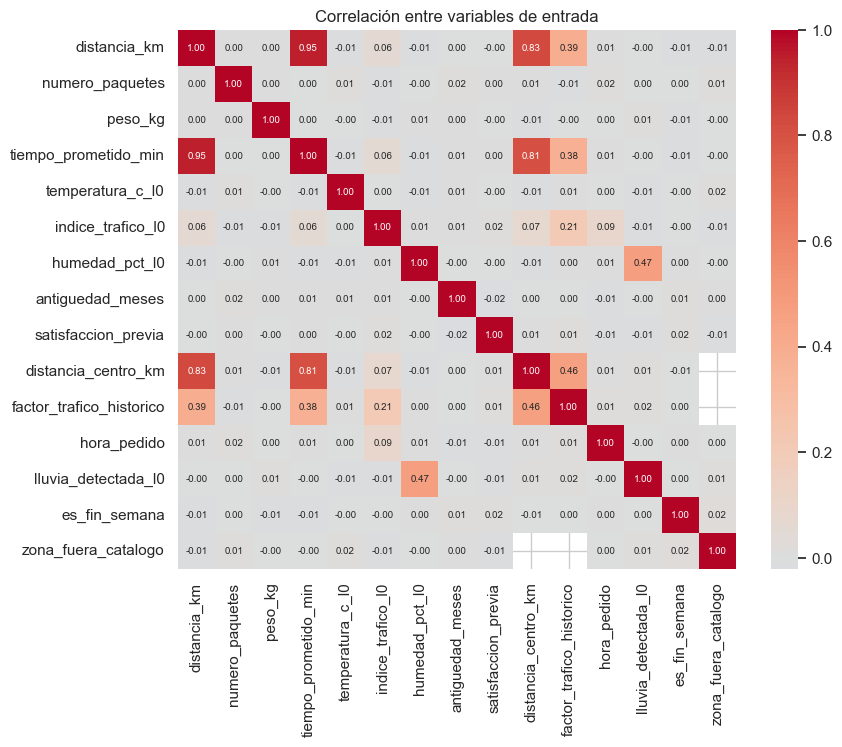

Pares con |r| > 0.7:


r
distancia_km         tiempo_prometido_min  0.949
                     distancia_centro_km   0.835
tiempo_prometido_min distancia_centro_km   0.810

Zonas vs sus atributos numéricos (nº de valores distintos por zona):


,distancia_centro_km,factor_trafico_historico
zona,,
Aeropuerto,1,1
Centro,1,1
Desconocida,0,0
Norte,1,1
Oriente,1,1
Poniente,1,1
Sur,1,1


In [22]:
# Lista final de variables de entrada
NUM = ['distancia_km', 'numero_paquetes', 'peso_kg', 'tiempo_prometido_min', 'temperatura_c_l0', 'indice_trafico_l0',
       'humedad_pct_l0', 'antiguedad_meses', 'satisfaccion_previa', 'distancia_centro_km', 'factor_trafico_historico', 'hora_pedido']
BIN = ['lluvia_detectada_l0', 'es_fin_semana', 'zona_fuera_catalogo']
ORD = ['prioridad']
NOM = ['tipo_servicio', 'tipo_cliente', 'canal_registro'] + (['alerta_climatica'] if 'alerta_climatica' in df.columns else [])
FEATURES = NUM + BIN + ORD + NOM
print(f'{len(FEATURES)} variables de entrada de {df.shape[1]} columnas del dataset integrado')

# Colinealidad entre predictores numéricos
corr = df[NUM + BIN].corr()
plt.figure(figsize=(9, 7)); sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 7}); plt.title('Correlación entre variables de entrada'); plt.show()
pares = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print('Pares con |r| > 0.7:'); display(pares[pares.abs() > 0.7].round(3).to_frame('r'))
print('Zonas vs sus atributos numéricos (nº de valores distintos por zona):'); display(df.groupby('zona')[['distancia_centro_km', 'factor_trafico_historico']].nunique())

Si aparecen pares con correlación alta (por ejemplo `distancia_km` y `tiempo_prometido_min`), se **conservan**: ambos están disponibles al crear el pedido y aportan información distinta (tiempo prometido incluye margen operativo). Solo se tiene presente que en la regresión lineal sus coeficientes individuales son menos interpretables por multicolinealidad.

## 7. Transformación de datos
Primero se **divide** en entrenamiento (80 %) y prueba (20 %), estratificando por `entrega_tardia`. Todo el preprocesamiento (imputación, codificación, escalado, PCA) se define como **Pipeline** y se ajusta (`fit`) **únicamente con entrenamiento**; sobre prueba solo se aplica `transform`. Así el conjunto de prueba nunca influye en el preprocesamiento.

| Técnica | Variables | Detalle |
|---|---|---|
| Imputación | numéricas | mediana + indicador de faltante (`add_indicator`) |
| Imputación | categóricas | moda (prioridad) / "Desconocido" (nominales) |
| Codificación ordinal | `prioridad` | Baja=0 < Media=1 < Alta=2 (respeta el orden) |
| Codificación one-hot | tipo de servicio, tipo de cliente, canal | `handle_unknown='ignore'` |
| Escalado | numéricas | `StandardScaler` (regresión y K-Means; el árbol no lo necesita) |
| Reducción | todas las variables transformadas | PCA (se usa en K-Means) + descarte de columnas de la sección 6 |

> Las variables con faltantes llevan un *indicador de faltante* (columna 0/1) en regresión y árbol, para que el modelo pueda distinguir un valor real de uno imputado. En K-Means **no** se usan indicadores, para que los grupos no se formen por el patrón de datos faltantes.

In [23]:
X = df[FEATURES].copy()
y_reg, y_clf = df['tiempo_real_min'], df['entrega_tardia']
X_train, X_test, yr_train, yr_test, yc_train, yc_test = train_test_split(
    X, y_reg, y_clf, test_size=0.2, random_state=SEED, stratify=y_clf)
print(f'Entrenamiento: {len(X_train):,} | Prueba: {len(X_test):,}')
print(f'Tasa de tardías -> entrenamiento: {yc_train.mean():.3f} | prueba: {yc_test.mean():.3f}')

def crear_prep(escalar=True, indicadores=True):
    paso_num = [('imp', SimpleImputer(strategy='median', add_indicator=indicadores))]
    if escalar: paso_num.append(('esc', StandardScaler()))
    paso_ord = [('imp', SimpleImputer(strategy='most_frequent')),
                ('cod', OrdinalEncoder(categories=[['Baja', 'Media', 'Alta']], handle_unknown='use_encoded_value', unknown_value=-1))]
    if escalar: paso_ord.append(('esc', StandardScaler()))
    ct = ColumnTransformer([
        ('num', Pipeline(paso_num), NUM),
        ('bin', SimpleImputer(strategy='most_frequent'), BIN),
        ('ord', Pipeline(paso_ord), ORD),
        ('nom', Pipeline([('imp', SimpleImputer(strategy='constant', fill_value='Desconocido')),
                          ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), NOM)],
        verbose_feature_names_out=False)
    ct.set_output(transform='pandas')
    return ct

prep_demo = crear_prep(escalar=True).fit(X_train)       # aprende SOLO con entrenamiento
Z_train, Z_test = prep_demo.transform(X_train), prep_demo.transform(X_test)
print(f'\nVariables de entrada originales: {X.shape[1]} -> columnas tras transformar: {Z_train.shape[1]}')
print('\nANTES (3 pedidos de entrenamiento):'); display(X_train.head(3).T)
print('DESPUÉS (imputado, codificado y escalado):'); display(Z_train.head(3).T.round(3))

Entrenamiento: 9,600 | Prueba: 2,400
Tasa de tardías -> entrenamiento: 0.344 | prueba: 0.343

Variables de entrada originales: 20 -> columnas tras transformar: 40

ANTES (3 pedidos de entrenamiento):


,9583,4190,4393
distancia_km,21.9,9.7,12.87
numero_paquetes,6.0,5.0,4.0
peso_kg,8.43,5.21,2.06
tiempo_prometido_min,73.0,52.2,45.5
temperatura_c_l0,14.508746,17.595344,26.408998
indice_trafico_l0,85.5,46.7,41.8
humedad_pct_l0,60.1,63.7,65.3
antiguedad_meses,26.0,27.0,29.0
satisfaccion_previa,2.0,3.0,5.0
distancia_centro_km,19.0,NaN,11.0


DESPUÉS (imputado, codificado y escalado):


,9583,4190,4393
distancia_km,1.424,-0.716,-0.160
numero_paquetes,0.648,0.213,-0.222
peso_kg,1.539,0.296,-0.920
tiempo_prometido_min,0.933,-0.254,-0.636
temperatura_c_l0,-1.915,-1.292,0.488
indice_trafico_l0,1.589,-0.435,-0.690
humedad_pct_l0,0.203,0.451,0.561
antiguedad_meses,0.042,0.112,0.250
satisfaccion_previa,-0.787,0.001,1.579
distancia_centro_km,1.627,0.225,-0.242


                      media_train  std_train  media_test  std_test
distancia_km                  0.0        1.0       0.005     0.998
tiempo_prometido_min          0.0        1.0      -0.003     0.996
indice_trafico_l0             0.0        1.0      -0.027     1.003

Componentes necesarios para conservar el 90% de la varianza: 21 de 40


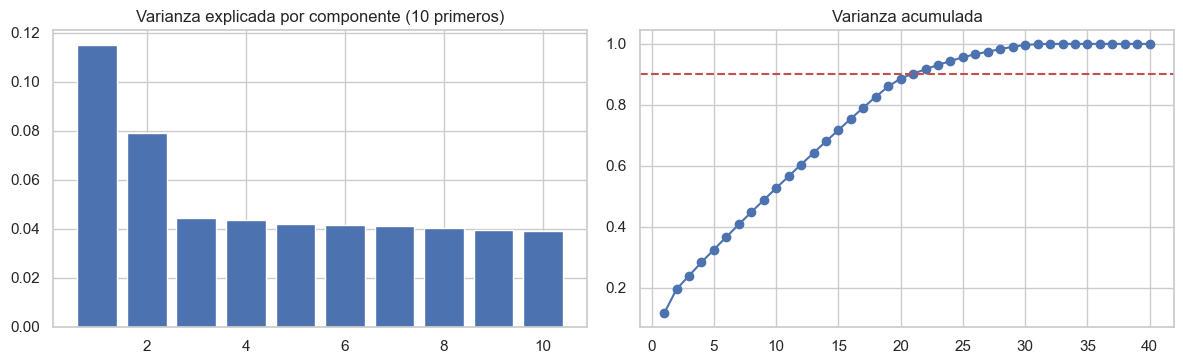

Variables con mayor peso en los primeros componentes:


,PC1,PC2
distancia_km,0.546,0.022
tiempo_prometido_min,0.543,0.024
distancia_centro_km,0.530,0.049
factor_trafico_historico,0.342,-0.046
indice_trafico_l0,0.085,-0.024
missingindicator_distancia_centro_km,-0.023,0.698
missingindicator_factor_trafico_historico,-0.023,0.698
hora_pedido,0.019,0.002


In [24]:
# Verificación: el escalado se aprendió con entrenamiento (train ≈ media 0 / desv. 1; prueba, no exactamente)
cols_esc = ['distancia_km', 'tiempo_prometido_min', 'indice_trafico_l0']
print(pd.DataFrame({'media_train': Z_train[cols_esc].mean(), 'std_train': Z_train[cols_esc].std(),
                    'media_test': Z_test[cols_esc].mean(), 'std_test': Z_test[cols_esc].std()}).round(3))

# Reducción de dimensionalidad con PCA (ajustado solo con entrenamiento)
pca_full = PCA(random_state=SEED).fit(Z_train)
acum = np.cumsum(pca_full.explained_variance_ratio_)
n90 = int(np.argmax(acum >= 0.90) + 1)
print(f'\nComponentes necesarios para conservar el 90% de la varianza: {n90} de {Z_train.shape[1]}')
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(range(1, 11), pca_full.explained_variance_ratio_[:10]); ax[0].set_title('Varianza explicada por componente (10 primeros)')
ax[1].plot(range(1, len(acum) + 1), acum, marker='o'); ax[1].axhline(.9, color='r', ls='--'); ax[1].set_title('Varianza acumulada')
plt.tight_layout(); plt.show()
carga = pd.DataFrame(pca_full.components_[:2].T, index=Z_train.columns, columns=['PC1', 'PC2'])
print('Variables con mayor peso en los primeros componentes:'); display(carga.reindex(carga['PC1'].abs().sort_values(ascending=False).index).head(8).round(3))
log('Reducción', 'modelado', 'todas las variables transformadas', f'{Z_train.shape[1]} columnas tras codificación', f'PCA con {n90} componentes (90% de varianza) para K-Means',
    0, f'{Z_train.shape[1]} columnas', f'{n90} componentes', 'Reduce redundancia/ruido para la distancia euclidiana de K-Means; se ajusta solo con entrenamiento')
log('Reducción', 'integrado', 'columnas', f'{df.shape[1]} columnas en el dataset integrado', 'Selección de variables (sección 6)', df.shape[1]-len(FEATURES), f'{df.shape[1]} columnas', f'{len(FEATURES)} variables de entrada',
    'Se descartan IDs, fugas, metadatos y redundantes con justificación en la tabla de selección')

## 8. Construcción de modelos
Todos los modelos se entrenan con `X_train` y se evalúan con `X_test` (datos que no vieron). Cada modelo se compara contra una **línea base**.

### 8.1 Regresión lineal — predecir `tiempo_real_min`
- **Línea base 1:** predecir siempre la media del entrenamiento.
- **Línea base 2:** usar directamente `tiempo_prometido_min` (lo que hace la empresa hoy).
- **Métricas:** MAE (error promedio en minutos, fácil de interpretar) y RMSE (penaliza más los errores grandes), además de R².

,modelo,MAE,RMSE,R2
0,Línea base: media de entrenamiento,17.433,21.355,-0.000
1,Línea base: tiempo prometido,9.592,12.072,0.680
2,Regresión lineal (prueba),8.208,10.346,0.765
3,Regresión lineal (entrenamiento),8.310,10.400,0.761


Validación cruzada (5 pliegues, solo entrenamiento) MAE: 8.338 ± 0.152


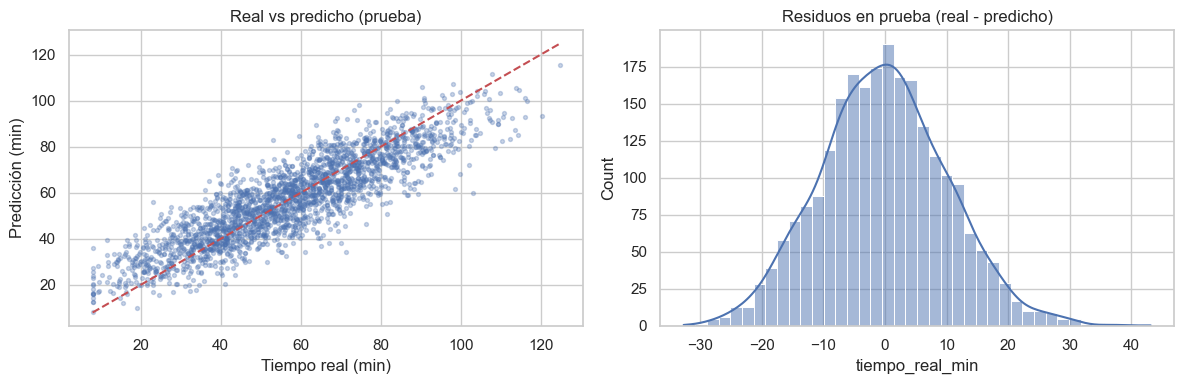

Coeficientes más influyentes (variables escaladas: comparables entre sí; unidades = minutos por desviación estándar):


,coeficiente
tiempo_prometido_min,17.254
lluvia_detectada_l0,10.232
numero_paquetes,3.111
indice_trafico_l0,1.986
tipo_cliente_Desconocido,-0.794
canal_registro_Desconocido,-0.794
peso_kg,0.604
canal_registro_Web,0.353
prioridad,0.295
tipo_cliente_Recurrente,0.287


In [25]:
reg = Pipeline([('prep', crear_prep(escalar=True)), ('lm', LinearRegression())])
reg.fit(X_train, yr_train)
pred_reg = reg.predict(X_test)

def met_reg(nombre, y, p):
    return dict(modelo=nombre, MAE=mean_absolute_error(y, p), RMSE=np.sqrt(mean_squared_error(y, p)), R2=r2_score(y, p))

base_media = np.full(len(yr_test), yr_train.mean())
res_reg = pd.DataFrame([
    met_reg('Línea base: media de entrenamiento', yr_test, base_media),
    met_reg('Línea base: tiempo prometido', yr_test, X_test['tiempo_prometido_min']),
    met_reg('Regresión lineal (prueba)', yr_test, pred_reg),
    met_reg('Regresión lineal (entrenamiento)', yr_train, reg.predict(X_train))]).round(3)
display(res_reg)

cv_mae = -cross_val_score(reg, X_train, yr_train, cv=5, scoring='neg_mean_absolute_error')
print(f'Validación cruzada (5 pliegues, solo entrenamiento) MAE: {cv_mae.mean():.3f} ± {cv_mae.std():.3f}')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(yr_test, pred_reg, alpha=.3, s=8); lim = [yr_test.min(), yr_test.max()]; ax[0].plot(lim, lim, 'r--')
ax[0].set_xlabel('Tiempo real (min)'); ax[0].set_ylabel('Predicción (min)'); ax[0].set_title('Real vs predicho (prueba)')
sns.histplot(yr_test - pred_reg, bins=40, kde=True, ax=ax[1]); ax[1].set_title('Residuos en prueba (real - predicho)')
plt.tight_layout(); plt.show()

coefs = pd.Series(reg['lm'].coef_, index=reg['prep'].get_feature_names_out()).sort_values(key=abs, ascending=False)
print('Coeficientes más influyentes (variables escaladas: comparables entre sí; unidades = minutos por desviación estándar):')
display(coefs.head(12).round(3).to_frame('coeficiente'))

### 8.2 Árbol de decisión — clasificar `entrega_tardia`
- **Desbalance:** se revisa la proporción de entregas tardías; si es minoritaria, la *exactitud* (accuracy) engaña, por lo que se prioriza **F1** (equilibrio entre precision y recall) y **recall** (no dejar pasar entregas que llegarán tarde).
- **Línea base:** predecir siempre la clase mayoritaria ("a tiempo").
- La profundidad y el balanceo de clases se eligen con validación cruzada **dentro del entrenamiento**.

Distribución de la etiqueta (entrenamiento): {0: 0.656, 1: 0.344}
Mejores hiperparámetros: {'tree__class_weight': 'balanced', 'tree__max_depth': 5, 'tree__min_samples_leaf': 20} | F1 en validación cruzada: 0.576


,modelo,accuracy,precision,recall,F1,AUC
0,"Línea base: siempre ""a tiempo""",0.657,0.000,0.000,0.000,NaN
1,Árbol de decisión (prueba),0.668,0.512,0.675,0.583,0.731
2,Árbol de decisión (entrenamiento),0.681,0.527,0.684,0.595,0.745


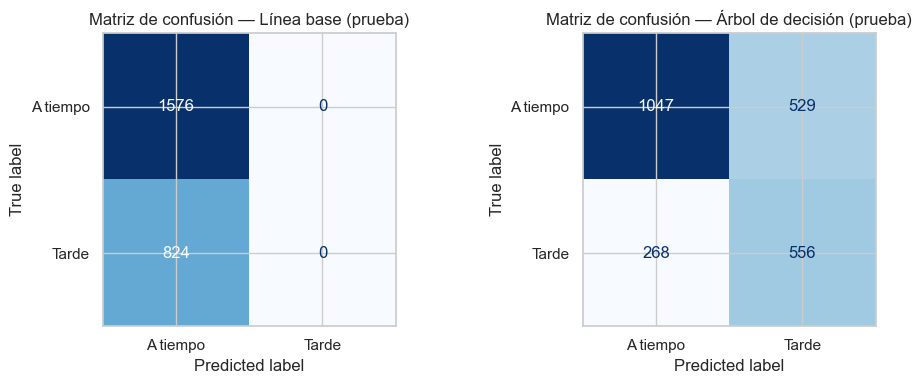

Verdaderos positivos: 556 | Falsos negativos (tardías no detectadas): 268 | Falsos positivos (falsas alarmas): 529 | Verdaderos negativos: 1047


In [26]:
print('Distribución de la etiqueta (entrenamiento):', yc_train.value_counts(normalize=True).round(3).to_dict())

base_clf = DummyClassifier(strategy='most_frequent').fit(X_train, yc_train)
arbol = Pipeline([('prep', crear_prep(escalar=False)), ('tree', DecisionTreeClassifier(random_state=SEED))])
grid = GridSearchCV(arbol, {'tree__max_depth': [3, 4, 5, 6, 8], 'tree__min_samples_leaf': [20, 50, 100],
                            'tree__class_weight': [None, 'balanced']}, scoring='f1', cv=5, n_jobs=-1)
grid.fit(X_train, yc_train)
arbol = grid.best_estimator_
print('Mejores hiperparámetros:', grid.best_params_, '| F1 en validación cruzada:', round(grid.best_score_, 3))

def met_clf(nombre, y, p, proba=None):
    return dict(modelo=nombre, accuracy=accuracy_score(y, p), precision=precision_score(y, p, zero_division=0),
                recall=recall_score(y, p), F1=f1_score(y, p), AUC=(roc_auc_score(y, proba) if proba is not None else np.nan))

pred_clf = arbol.predict(X_test); proba_clf = arbol.predict_proba(X_test)[:, 1]
res_clf = pd.DataFrame([met_clf('Línea base: siempre "a tiempo"', yc_test, base_clf.predict(X_test)),
                        met_clf('Árbol de decisión (prueba)', yc_test, pred_clf, proba_clf),
                        met_clf('Árbol de decisión (entrenamiento)', yc_train, arbol.predict(X_train), arbol.predict_proba(X_train)[:, 1])]).round(3)
display(res_clf)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a_, pr, t in zip(ax, [base_clf.predict(X_test), pred_clf], ['Línea base', 'Árbol de decisión']):
    ConfusionMatrixDisplay(confusion_matrix(yc_test, pr), display_labels=['A tiempo', 'Tarde']).plot(ax=a_, colorbar=False, cmap='Blues'); a_.set_title(f'Matriz de confusión — {t} (prueba)')
plt.tight_layout(); plt.show()
tn, fp_, fn, tp = confusion_matrix(yc_test, pred_clf).ravel()
print(f'Verdaderos positivos: {tp} | Falsos negativos (tardías no detectadas): {fn} | Falsos positivos (falsas alarmas): {fp_} | Verdaderos negativos: {tn}')

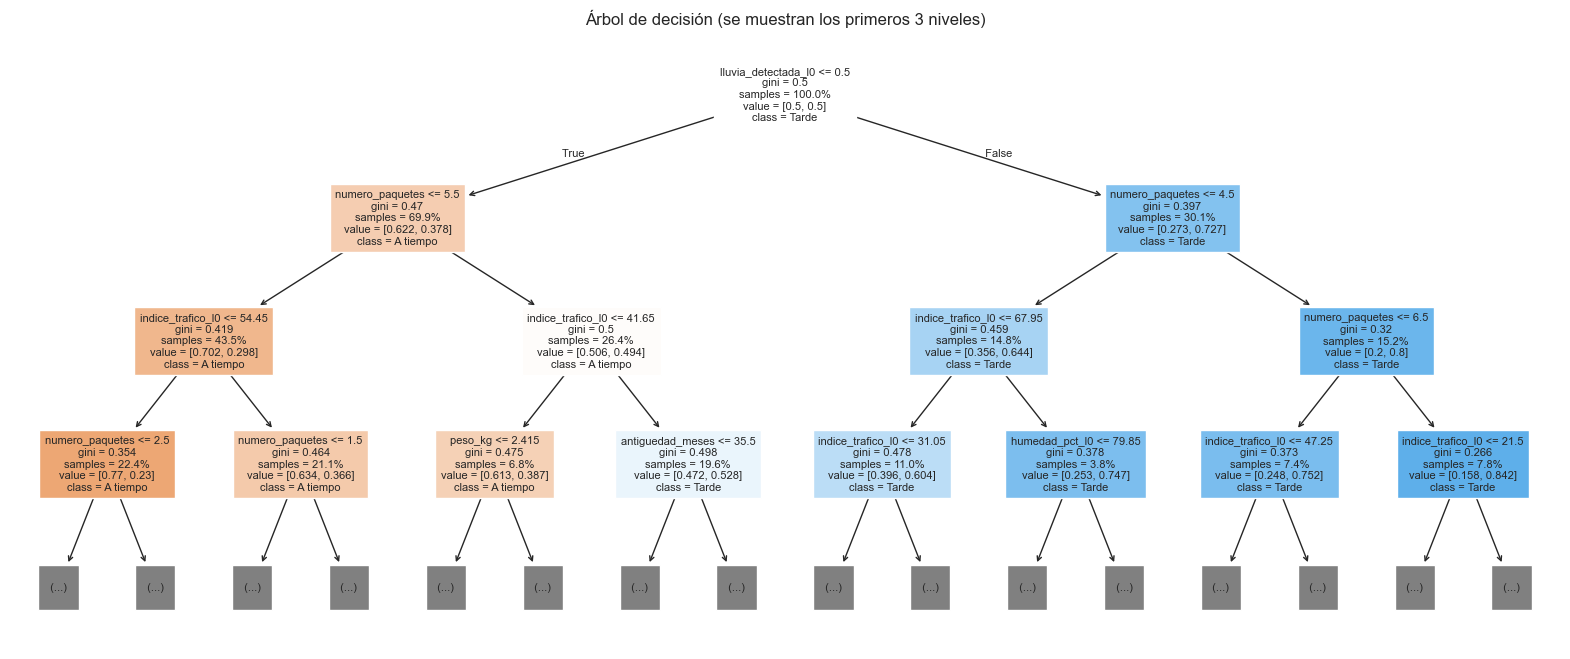

,importancia (impureza)
lluvia_detectada_l0,0.600
numero_paquetes,0.221
indice_trafico_l0,0.097
peso_kg,0.027
tiempo_prometido_min,0.010
factor_trafico_historico,0.007
canal_registro_Web,0.006
temperatura_c_l0,0.006
antiguedad_meses,0.006
alerta_climatica_Sin alerta,0.006


In [27]:
# Estructura del árbol (primeros 3 niveles) e importancia por impureza
arbol_fit = arbol['tree']; nombres_t = arbol['prep'].get_feature_names_out()
plt.figure(figsize=(20, 8))
plot_tree(arbol_fit, feature_names=nombres_t, class_names=['A tiempo', 'Tarde'], max_depth=3, filled=True, fontsize=8, proportion=True)
plt.title('Árbol de decisión (se muestran los primeros 3 niveles)'); plt.show()
imp_arbol = pd.Series(arbol_fit.feature_importances_, index=nombres_t).sort_values(ascending=False)
display(imp_arbol.head(10).round(3).to_frame('importancia (impureza)'))

### 8.3 Reglas SI–ENTONCES
Las reglas se obtienen de las **hojas de un árbol poco profundo** (más fácil de leer), entrenado con el conjunto de entrenamiento. Cada regla se **comprueba con los datos** midiendo:
- **Soporte:** % de pedidos que cumplen la condición.
- **Confianza:** % de esos pedidos que realmente llegaron tarde.
- **Lift:** cuántas veces mayor es la confianza respecto de la tasa global de retraso (lift > 1 = la regla identifica más retrasos que el azar).

Se calculan en entrenamiento y se **verifican en prueba**.

In [28]:
prep_tr = crear_prep(escalar=False).fit(X_train)
Xt_tr, Xt_te = prep_tr.transform(X_train), prep_tr.transform(X_test)
arbol_reglas = DecisionTreeClassifier(max_depth=4, min_samples_leaf=150, random_state=SEED).fit(Xt_tr, yc_train)
nombres_r = list(Xt_tr.columns)

def hojas(clf):
    t, out = clf.tree_, []
    def rec(n, cond):
        if t.children_left[n] == -1: out.append(cond); return
        f, th = nombres_r[t.feature[n]], t.threshold[n]
        rec(t.children_left[n], cond + [(f, '<=', th)]); rec(t.children_right[n], cond + [(f, '>', th)])
    rec(0, []); return out

def aplicar(cond, Xt):
    m = pd.Series(True, index=Xt.index)
    for f, op, th in cond: m &= (Xt[f] <= th) if op == '<=' else (Xt[f] > th)
    return m

def texto(cond):
    lim = {}
    for f, op, th in cond:
        lo, hi = lim.get(f, (-np.inf, np.inf))
        lim[f] = (lo, min(hi, th)) if op == '<=' else (max(lo, th), hi)
    partes = []
    for f, (lo, hi) in lim.items():
        cat = next(((n_, f[len(n_) + 1:]) for n_ in NOM if f.startswith(n_ + '_')), None)
        if cat: partes.append(f'{cat[0]} {"≠" if hi < np.inf else "="} {cat[1]}')
        elif f == 'prioridad':
            vals = [n_ for v, n_ in enumerate(['Baja', 'Media', 'Alta']) if lo < v <= hi]
            partes.append('prioridad ' + ('= ' + vals[0] if len(vals) == 1 else 'en {' + ', '.join(vals) + '}'))
        elif f in BIN: partes.append(f'{f} {"= 0" if hi < np.inf else "= 1"}')
        elif lo > -np.inf and hi < np.inf: partes.append(f'{lo:.2f} < {f} ≤ {hi:.2f}')
        elif lo > -np.inf: partes.append(f'{f} > {lo:.2f}')
        else: partes.append(f'{f} ≤ {hi:.2f}')
    return ' Y '.join(partes)

base_tr, base_te = yc_train.mean(), yc_test.mean()
filas = []
for cond in hojas(arbol_reglas):
    m_tr, m_te = aplicar(cond, Xt_tr), aplicar(cond, Xt_te)
    if m_tr.sum() == 0 or m_te.sum() == 0: continue
    filas.append(dict(regla=texto(cond), cond=cond, soporte_train=m_tr.mean(), confianza_train=yc_train[m_tr].mean(), lift_train=yc_train[m_tr].mean()/base_tr,
                      soporte_test=m_te.mean(), confianza_test=yc_test[m_te].mean(), lift_test=yc_test[m_te].mean()/base_te))
reglas_df = pd.DataFrame(filas)
sel = reglas_df[reglas_df['soporte_train'] >= 0.03].sort_values('lift_train', ascending=False).head(3).reset_index(drop=True)

print(f'Tasa global de entregas tardías: entrenamiento {base_tr:.1%} | prueba {base_te:.1%}\n')
for i, r in sel.iterrows():
    print(f'REGLA {i+1}: SI {r["regla"]}\n          ENTONCES la entrega será TARDÍA')
    print(f'   entrenamiento -> soporte {r["soporte_train"]:.1%} | confianza {r["confianza_train"]:.1%} | lift {r["lift_train"]:.2f}')
    print(f'   prueba        -> soporte {r["soporte_test"]:.1%} | confianza {r["confianza_test"]:.1%} | lift {r["lift_test"]:.2f}\n')
display(sel.drop(columns='cond').round(3))

# Una regla complementaria: condiciones asociadas a entregas a tiempo
opuesta = reglas_df[reglas_df['soporte_train'] >= 0.03].sort_values('confianza_train').head(1).reset_index(drop=True)
for _, r in opuesta.iterrows():
    print(f'Regla de contraste: SI {r["regla"]} ENTONCES lo más probable es que llegue A TIEMPO '
          f'(solo {r["confianza_test"]:.1%} tardías en prueba; soporte {r["soporte_test"]:.1%})')

Tasa global de entregas tardías: entrenamiento 34.4% | prueba 34.3%

REGLA 1: SI lluvia_detectada_l0 = 1 Y numero_paquetes > 6.50 Y factor_trafico_historico > 1.20
          ENTONCES la entrega será TARDÍA
   entrenamiento -> soporte 3.9% | confianza 79.1% | lift 2.30
   prueba        -> soporte 3.8% | confianza 77.8% | lift 2.27

REGLA 2: SI lluvia_detectada_l0 = 1 Y numero_paquetes > 6.50 Y factor_trafico_historico ≤ 1.20
          ENTONCES la entrega será TARDÍA
   entrenamiento -> soporte 3.9% | confianza 68.2% | lift 1.98
   prueba        -> soporte 3.6% | confianza 75.6% | lift 2.20

REGLA 3: SI lluvia_detectada_l0 = 1 Y 4.50 < numero_paquetes ≤ 6.50 Y indice_trafico_l0 > 47.25
          ENTONCES la entrega será TARDÍA
   entrenamiento -> soporte 4.7% | confianza 66.1% | lift 1.92
   prueba        -> soporte 5.8% | confianza 61.4% | lift 1.79



,regla,soporte_train,confianza_train,lift_train,soporte_test,confianza_test,lift_test
0,lluvia_detectada_l0 = 1 Y numero_paquetes > 6.50 Y facto...,0.039,0.791,2.302,0.038,0.778,2.265
1,lluvia_detectada_l0 = 1 Y numero_paquetes > 6.50 Y facto...,0.039,0.682,1.984,0.036,0.756,2.201
2,lluvia_detectada_l0 = 1 Y 4.50 < numero_paquetes ≤ 6.50 ...,0.047,0.661,1.923,0.058,0.614,1.789


Regla de contraste: SI lluvia_detectada_l0 = 0 Y numero_paquetes ≤ 2.50 Y indice_trafico_l0 ≤ 69.15 ENTONCES lo más probable es que llegue A TIEMPO (solo 9.1% tardías en prueba; soporte 11.4%)


### 8.4 K-Means — grupos de pedidos
- Se usan **solo variables previas a la entrega** (las mismas `FEATURES`), imputadas, codificadas, escaladas y reducidas con PCA (90 % de varianza), todo ajustado con entrenamiento. No se incluyen indicadores de faltante para que los grupos reflejen el tipo de pedido y no el patrón de datos perdidos.
- El número de grupos `k` se elige con **inercia (codo)** y **coeficiente de silueta**, explorando de 2 a 8 grupos y eligiendo entre 3 y 6 (el de mayor silueta), para que la segmentación sea interpretable y útil operativamente.
- La tasa de retraso y el tiempo real **no entran al clustering**: se usan después, solo para *interpretar* los grupos.
- **Línea base:** silueta de una asignación aleatoria (≈ 0 = sin estructura).

PCA para K-Means: 15 componentes conservan 90.5% de la varianza


,k,inercia,silueta
0,2,116583.568,0.137
1,3,110121.358,0.104
2,4,106235.467,0.072
3,5,102899.370,0.074
4,6,99853.005,0.074
5,7,97556.034,0.071
6,8,95804.453,0.067


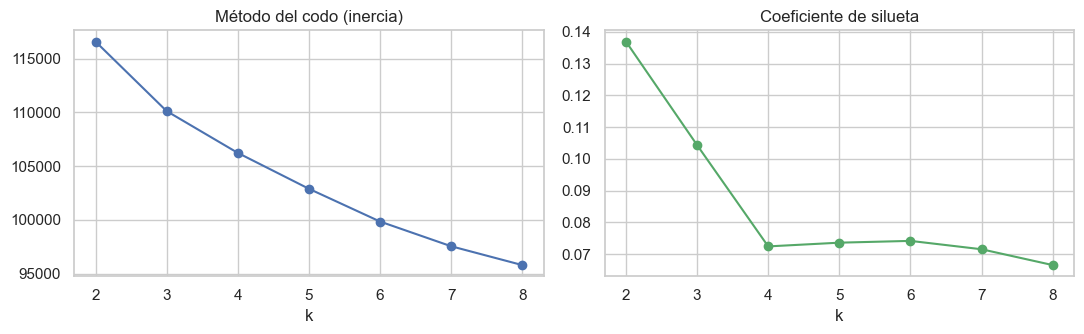


k elegido = 3
Silueta en prueba: 0.110 | línea base (etiquetas aleatorias): -0.004


In [29]:
prep_km = crear_prep(escalar=True, indicadores=False).fit(X_train)
pca_km = PCA(n_components=0.90, random_state=SEED).fit(prep_km.transform(X_train))
P_tr, P_te = pca_km.transform(prep_km.transform(X_train)), pca_km.transform(prep_km.transform(X_test))
print(f'PCA para K-Means: {pca_km.n_components_} componentes conservan {pca_km.explained_variance_ratio_.sum():.1%} de la varianza')

busqueda = []
for k in range(2, 9):
    km_ = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(P_tr)
    busqueda.append(dict(k=k, inercia=km_.inertia_, silueta=silhouette_score(P_tr, km_.labels_, sample_size=3000, random_state=SEED)))
busqueda = pd.DataFrame(busqueda); display(busqueda.round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(busqueda['k'], busqueda['inercia'], marker='o'); ax[0].set_title('Método del codo (inercia)'); ax[0].set_xlabel('k')
ax[1].plot(busqueda['k'], busqueda['silueta'], marker='o', color='g'); ax[1].set_title('Coeficiente de silueta'); ax[1].set_xlabel('k')
plt.tight_layout(); plt.show()

K = int(busqueda[busqueda['k'].between(3, 6)].sort_values('silueta', ascending=False).iloc[0]['k'])
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(P_tr)
lab_tr, lab_te = km.labels_, km.predict(P_te)
rng = np.random.RandomState(SEED)
print(f'\nk elegido = {K}')
print(f'Silueta en prueba: {silhouette_score(P_te, lab_te, sample_size=3000, random_state=SEED):.3f} | línea base (etiquetas aleatorias): {silhouette_score(P_te, rng.randint(0, K, len(P_te)), sample_size=3000, random_state=SEED):.3f}')

,pedidos,distancia_km,paquetes,peso_kg,prometido_min,trafico_sensor,factor_trafico_zona,pct_expres,pct_prioridad_alta,pct_lluvia,antiguedad_meses,satisfaccion_previa,tiempo_real_min,tasa_tardia,pct_pedidos
grupo,,,,,,,,,,,,,,,
0,4696,11.989,4.508,4.459,51.397,49.501,1.110,0.289,0.247,0.299,25.134,2.974,51.446,0.326,48.9
1,3277,19.761,4.519,4.469,74.394,60.382,1.291,0.297,0.256,0.305,25.672,3.017,75.769,0.359,34.1
2,1627,6.865,4.461,4.475,36.049,60.585,1.288,0.309,0.266,0.296,25.375,3.027,37.299,0.364,16.9


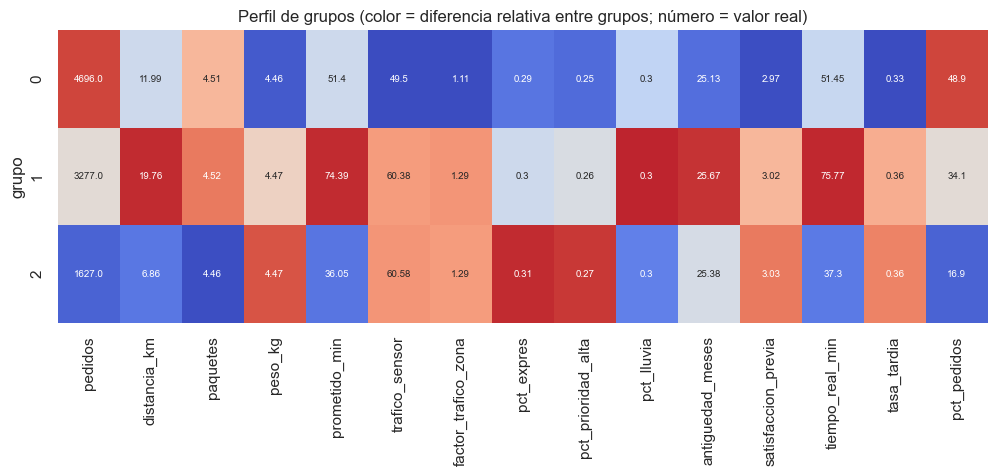

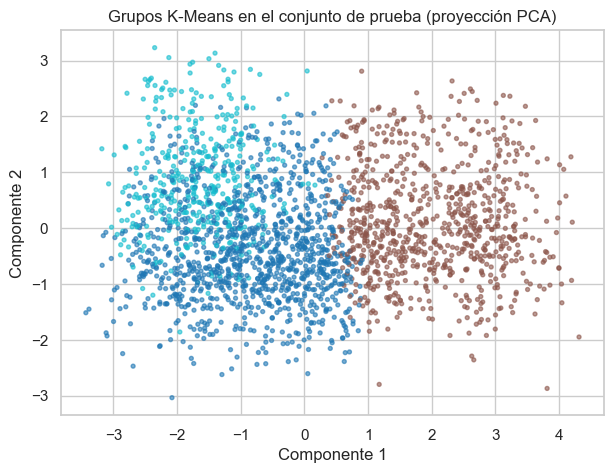

In [30]:
# Interpretación de los grupos (sobre datos originales, sin escalar)
perfil_df = df.loc[X_train.index].assign(grupo=lab_tr)
perfil = perfil_df.groupby('grupo').agg(
    pedidos=('pedido_id', 'count'), distancia_km=('distancia_km', 'mean'), paquetes=('numero_paquetes', 'mean'), peso_kg=('peso_kg', 'mean'),
    prometido_min=('tiempo_prometido_min', 'mean'), trafico_sensor=('indice_trafico_l0', 'mean'), factor_trafico_zona=('factor_trafico_historico', 'mean'),
    pct_expres=('tipo_servicio', lambda x: (x == 'Exprés').mean()), pct_prioridad_alta=('prioridad', lambda x: (x == 'Alta').mean()),
    pct_lluvia=('lluvia_detectada_l0', 'mean'), antiguedad_meses=('antiguedad_meses', 'mean'), satisfaccion_previa=('satisfaccion_previa', 'mean'),
    # solo para interpretar (no entran al clustering):
    tiempo_real_min=('tiempo_real_min', 'mean'), tasa_tardia=('entrega_tardia', 'mean')).round(3)
perfil['pct_pedidos'] = (100*perfil['pedidos']/perfil['pedidos'].sum()).round(1)
display(perfil)

plt.figure(figsize=(12, 3.8))
sns.heatmap((perfil - perfil.mean())/perfil.std(), annot=perfil.round(2), fmt='', cmap='coolwarm', center=0, cbar=False, annot_kws={'size': 7}); plt.title('Perfil de grupos (color = diferencia relativa entre grupos; número = valor real)'); plt.show()

plt.figure(figsize=(7, 5)); plt.scatter(P_te[:, 0], P_te[:, 1], c=lab_te, cmap='tab10', s=8, alpha=.6)
plt.xlabel('Componente 1'); plt.ylabel('Componente 2'); plt.title('Grupos K-Means en el conjunto de prueba (proyección PCA)'); plt.show()

**Interpretación de los grupos:** con k = 3 los grupos se separan sobre todo por **distancia, tiempo prometido y factor de tráfico de la zona**: un grupo de pedidos largos (~20 km, ~74 min prometidos, zonas de mayor tráfico histórico), uno de pedidos cortos (~7 km, ~36 min) y uno intermedio (~12 km) en zonas de menor tráfico. Las variables del cliente, el peso y los paquetes casi no cambian entre grupos. La tasa de retraso es parecida en los tres (≈ 33–36 %): la distancia hace que el pedido sea *más largo*, pero no necesariamente *más tardío* respecto de lo prometido. El coeficiente de silueta es bajo (≈ 0.1), por lo que los grupos deben leerse como una **segmentación descriptiva** de un continuo, no como categorías naturales bien separadas.

## 9. Evaluación e interpretación
### 9.1 Resumen de métricas (todas calculadas sobre el conjunto de prueba)

In [31]:
print('REGRESIÓN LINEAL'); display(res_reg.iloc[[0, 1, 2]].set_index('modelo'))
print('ÁRBOL DE DECISIÓN'); display(res_clf.iloc[[0, 1]].set_index('modelo'))
mejora = 1 - res_reg.loc[2, 'MAE']/res_reg.loc[1, 'MAE']
print(f'La regresión lineal reduce el MAE {mejora:.1%} frente a usar el tiempo prometido y {1 - res_reg.loc[2, "MAE"]/res_reg.loc[0, "MAE"]:.1%} frente a la media.')
print(f'El árbol detecta {tp} de {tp+fn} entregas tardías de prueba (recall {recall_score(yc_test, pred_clf):.1%}) con precision {precision_score(yc_test, pred_clf):.1%}.')

REGRESIÓN LINEAL


,MAE,RMSE,R2
modelo,,,
Línea base: media de entrenamiento,17.433,21.355,-0.000
Línea base: tiempo prometido,9.592,12.072,0.680
Regresión lineal (prueba),8.208,10.346,0.765


ÁRBOL DE DECISIÓN


,accuracy,precision,recall,F1,AUC
modelo,,,,,
"Línea base: siempre ""a tiempo""",0.657,0.000,0.000,0.000,NaN
Árbol de decisión (prueba),0.668,0.512,0.675,0.583,0.731


La regresión lineal reduce el MAE 14.4% frente a usar el tiempo prometido y 52.9% frente a la media.
El árbol detecta 556 de 824 entregas tardías de prueba (recall 67.5%) con precision 51.2%.


**Justificación de métricas**
- **MAE** responde "¿cuántos minutos nos equivocamos en promedio?"; **RMSE** castiga los errores grandes, que son los que más molestan al cliente.
- En clasificación, la **exactitud sola no sirve** si hay mayoría de entregas a tiempo (la línea base ya obtiene una exactitud alta sin detectar ningún retraso). Por eso se reportan **precision, recall y F1**: el recall mide cuántos retrasos reales se anticipan; la precision, cuántas alertas fueron correctas.

### 9.2 Importancia de variables

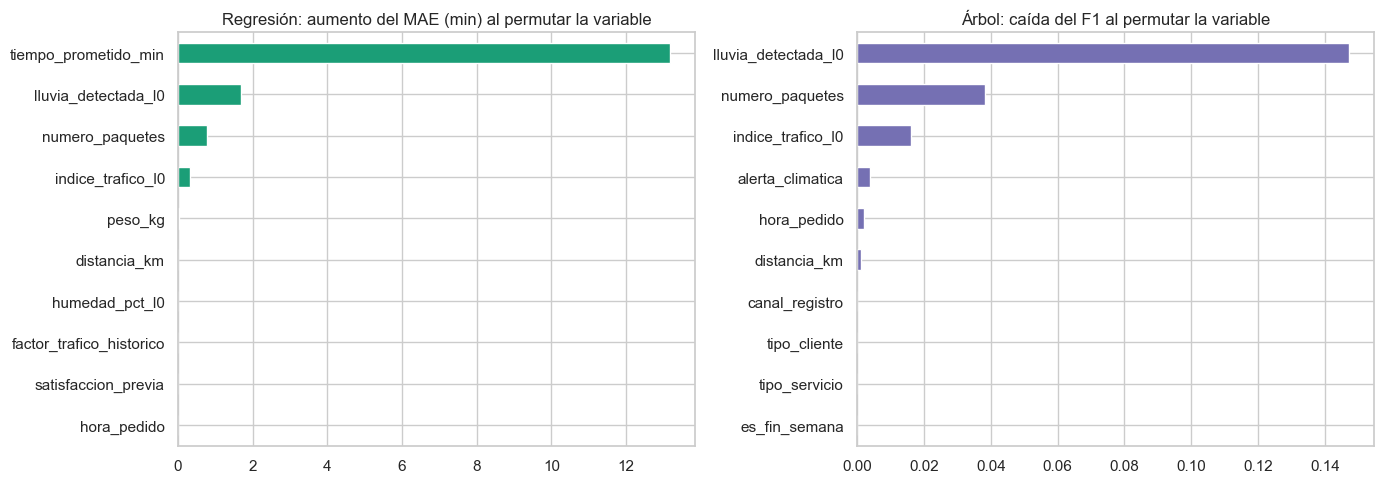

Top 5 regresión: ['tiempo_prometido_min', 'lluvia_detectada_l0', 'numero_paquetes', 'indice_trafico_l0', 'peso_kg']
Top 5 árbol    : ['lluvia_detectada_l0', 'numero_paquetes', 'indice_trafico_l0', 'alerta_climatica', 'hora_pedido']


In [32]:
imp_reg = permutation_importance(reg, X_test, yr_test, scoring='neg_mean_absolute_error', n_repeats=10, random_state=SEED, n_jobs=-1)
imp_clf = permutation_importance(arbol, X_test, yc_test, scoring='f1', n_repeats=10, random_state=SEED, n_jobs=-1)
imp_r = pd.Series(imp_reg.importances_mean, index=X_test.columns).sort_values()
imp_c = pd.Series(imp_clf.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
imp_r.tail(10).plot.barh(ax=ax[0], color='#1b9e77'); ax[0].set_title('Regresión: aumento del MAE (min) al permutar la variable')
imp_c.tail(10).plot.barh(ax=ax[1], color='#7570b3'); ax[1].set_title('Árbol: caída del F1 al permutar la variable')
plt.tight_layout(); plt.show()
print('Top 5 regresión:', list(imp_r.tail(5).index[::-1])); print('Top 5 árbol    :', list(imp_c.tail(5).index[::-1]))

**Qué variables resultaron más importantes:** en la regresión destaca `tiempo_prometido_min` (que resume distancia y condiciones del servicio), seguida de la lluvia detectada al crear el pedido y el número de paquetes. En el árbol, la **lluvia**, el **número de paquetes** y el **índice de tráfico** son las que más sostienen la clasificación; las variables del cliente aportan muy poco. Los resultados son coherentes con las reglas SI–ENTONCES: los retrasos se concentran en pedidos con lluvia, muchos paquetes y tráfico alto.

La importancia por permutación mide cuánto empeora el modelo **en datos de prueba** cuando se desordena una variable (se calcula por variable original, sin importar cuántas columnas genere la codificación). Las variables con barras más largas son las que más sostienen la predicción; las cercanas a cero aportan poco o nada.

### 9.3 Revisión de posibles sesgos: desempeño por zona y tipo de cliente

In [33]:
aud = df.loc[X_test.index, ['zona', 'tipo_cliente']].assign(real=yr_test, pred=pred_reg, y=yc_test, yhat=pred_clf)
aud['err_abs'] = (aud['real'] - aud['pred']).abs()
def resumen_grupo(g):
    return pd.Series({'pedidos': len(g), 'MAE_min': g['err_abs'].mean(), 'tasa_tardia_real': g['y'].mean(),
                      'recall': recall_score(g['y'], g['yhat']) if g['y'].sum() else np.nan,
                      'precision': precision_score(g['y'], g['yhat'], zero_division=0)})
print('Por zona:'); display(aud.groupby('zona').apply(resumen_grupo).round(3))
print('Por tipo de cliente:'); display(aud.groupby('tipo_cliente').apply(resumen_grupo).round(3))

Por zona:


,pedidos,MAE_min,tasa_tardia_real,recall,precision
zona,,,,,
Aeropuerto,395.0,8.073,0.367,0.683,0.524
Centro,384.0,8.174,0.370,0.676,0.527
Desconocida,30.0,7.389,0.100,0.667,0.222
Norte,394.0,8.236,0.289,0.702,0.494
Oriente,409.0,8.543,0.379,0.619,0.500
Poniente,404.0,7.969,0.332,0.701,0.519
Sur,384.0,8.314,0.341,0.679,0.524


Por tipo de cliente:


,pedidos,MAE_min,tasa_tardia_real,recall,precision
tipo_cliente,,,,,
Desconocido,35.0,6.643,0.286,0.800,0.444
Empresa,473.0,8.528,0.347,0.720,0.520
Nuevo,575.0,8.260,0.353,0.650,0.494
Recurrente,1317.0,8.113,0.339,0.667,0.520


Si el error o el recall difieren de forma notable entre grupos (por ejemplo, en la zona "Desconocida", con pocos pedidos y atributos imputados), el modelo sería menos confiable justo para esos clientes. Eso debe considerarse antes de usarlo para priorizar o penalizar zonas o tipos de cliente.

### 9.4 GIGO — ejemplo 2: los defectos alteran las predicciones
Se entrena **el mismo modelo** (regresión lineal con mediana + escalado) sobre las mismas filas de entrenamiento y se evalúa sobre las mismas filas de prueba, pero con dos versiones de las variables numéricas: **crudas** (con centinelas, textos y formatos) y **limpias**.

In [34]:
cols_g = ['distancia_km', 'numero_paquetes', 'peso_kg', 'tiempo_prometido_min', 'temperatura_c_l0', 'indice_trafico_l0', 'humedad_pct_l0', 'antiguedad_meses', 'lluvia_detectada_l0']
sucio = df_int[cols_g].apply(pd.to_numeric, errors='coerce')     # sin corregir formatos ni centinelas
limpio = df[cols_g]
def entrenar(Xd):
    m = Pipeline([('imp', SimpleImputer(strategy='median')), ('esc', StandardScaler()), ('lm', LinearRegression())])
    m.fit(Xd.loc[X_train.index], yr_train); p_ = m.predict(Xd.loc[X_test.index])
    return mean_absolute_error(yr_test, p_), np.sqrt(mean_squared_error(yr_test, p_)), r2_score(yr_test, p_)
g = pd.DataFrame({'Datos crudos': entrenar(sucio), 'Datos limpios': entrenar(limpio)}, index=['MAE (min)', 'RMSE (min)', 'R²']).T.round(3)
display(g)
print(f'Con datos crudos el MAE es {100*(g.loc["Datos crudos", "MAE (min)"]/g.loc["Datos limpios", "MAE (min)"] - 1):.1f}% mayor que con datos limpios (mismo modelo, mismas filas).')

# Ejemplo 2b: además, los formatos mal leídos hacen perder la variable más importante
perdidas = int(pd.to_numeric(df_int['distancia_km'], errors='coerce').isna().sum()); recuperadas = int(df['distancia_km'].isna().sum())
print(f'distancia_km sin limpiar: {perdidas} pedidos sin valor (por "12,5", "8 km", "n/d"); tras la limpieza solo quedan {recuperadas} verdaderamente faltantes.')

,MAE (min),RMSE (min),R²
Datos crudos,8.580,10.801,0.744
Datos limpios,8.187,10.330,0.766


Con datos crudos el MAE es 4.8% mayor que con datos limpios (mismo modelo, mismas filas).
distancia_km sin limpiar: 567 pedidos sin valor (por "12,5", "8 km", "n/d"); tras la limpieza solo quedan 382 verdaderamente faltantes.


## 10. Guardado de datasets limpios
Se exportan a la carpeta `datasets_limpios/`:

| Archivo | Contenido |
|---|---|
| `dataset_limpio_imputado.csv` | Dataset integrado (1 fila por pedido), limpio y **sin nulos** en las variables predictoras (imputación por mediana/moda con banderas `*_imputado`). |
| `dataset_limpio_con_nulos.csv` | Mismo dataset limpio pero **conservando los `NaN`** (útil para volver a imputar con otro criterio). |
| `dataset_modelado_train.csv` / `dataset_modelado_test.csv` | Variables de entrada + objetivos de las particiones de entrenamiento y prueba. |
| `diccionario_variables.csv` | Diccionario de variables del dataset limpio. |
| `bitacora_limpieza.csv` | Bitácora antes/después de cada decisión. |
| `auditoria_calidad.csv` | Tabla de hallazgos de calidad (número y porcentaje). |

> Nota: el CSV imputado es un producto de entrega (descriptivo). Los modelos **no** lo usan: imputan dentro de su Pipeline aprendiendo solo del entrenamiento.

In [35]:
OUT = 'datasets_limpios'; os.makedirs(OUT, exist_ok=True)

# Dataset imputado (producto de entrega): medianas/modas; los posteriores de la encuesta NO se imputan
df_export = df.copy()
imputables_num = NUM + ['numero_paquetes'] + [c_ for c_ in df.columns if c_.endswith(('_l1',)) and df[c_].dtype != 'O' and 'fecha' not in c_]
imputables_num = list(dict.fromkeys([c_ for c_ in imputables_num if c_ in df.columns and c_ not in ('hora_pedido',)]))
for c_ in imputables_num:
    if df_export[c_].isna().any():
        df_export[f'{c_}_imputado'] = df_export[c_].isna().astype(int)
        df_export[c_] = df_export[c_].fillna(df_export[c_].median())
df_export['canal_registro'] = df_export['canal_registro'].fillna('Desconocido')
df_export['prioridad_imputado'] = df_export['prioridad'].isna().astype(int)
df_export['prioridad'] = df_export['prioridad'].fillna(df_export['prioridad'].mode()[0])
print('Nulos restantes (variables posteriores de la encuesta y metadato ultima_actualizacion: no se imputan):'); print(df_export.isna().sum()[lambda x: x > 0].to_dict())

df_export.to_csv(f'{OUT}/dataset_limpio_imputado.csv', index=False, encoding='utf-8-sig')
df.to_csv(f'{OUT}/dataset_limpio_con_nulos.csv', index=False, encoding='utf-8-sig')
X_train.assign(tiempo_real_min=yr_train, entrega_tardia=yc_train).to_csv(f'{OUT}/dataset_modelado_train.csv', encoding='utf-8-sig')
X_test.assign(tiempo_real_min=yr_test, entrega_tardia=yc_test).to_csv(f'{OUT}/dataset_modelado_test.csv', encoding='utf-8-sig')
pd.DataFrame(bitacora).to_csv(f'{OUT}/bitacora_limpieza.csv', index=False, encoding='utf-8-sig')
tabla_calidad.to_csv(f'{OUT}/auditoria_calidad.csv', index=False, encoding='utf-8-sig')

# Diccionario de variables del dataset limpio
base = tipos.set_index('variable')
extra = {
 'fecha_pedido_reconstruida': ('Numérica', 'Binaria', 'Metadato', 'Sí', '1 si la fecha del pedido se reconstruyó (fecha_entrega - tiempo_real_min)'),
 'zona_fuera_catalogo': ('Categórica', 'Binaria', 'Predictor', 'Sí', '1 si el zona_id no existe en el catálogo (Z99)'),
 'hora_pedido': ('Numérica', 'Discreta', 'Predictor', 'Sí', 'Hora del día en que se creó el pedido'),
 'dia_semana': ('Numérica', 'Discreta', 'Metadato', 'Sí', 'Día de la semana (0=lunes)'),
 'es_fin_semana': ('Categórica', 'Binaria', 'Predictor', 'Sí', '1 si el pedido se creó en sábado o domingo'),
 'demora_min': ('Numérica', 'Continua', 'Posterior', 'No', 'tiempo_real_min - tiempo_prometido_min'),
 'alerta_climatica': ('Categórica', 'Nominal', 'Predictor', 'Sí', 'Alerta climática externa por fecha y zona'),
}
def info(col):
    if col.endswith('_imputado'): return ('Numérica', 'Binaria', 'Metadato', 'Sí', f'1 si {col[:-9]} fue imputado')
    if col in extra: return extra[col]
    b = re.sub(r'_l[01]$', '', col)
    if b in base.index:
        r = base.loc[b]; disp = r['disponible_al_crear_pedido']
        if col.endswith('_l1'): disp = 'No (posterior al pedido)'
        if col.endswith('_l0'): disp = 'Sí (lectura _0)'
        suf = ' — lectura 0 (al crear el pedido)' if col.endswith('_l0') else ' — lectura 1 (minutos después)' if col.endswith('_l1') else ''
        return (r['clase'], r['subtipo'], r['rol'], disp, r['descripcion'] + suf)
    return ('—', '—', '—', '—', '—')
dic = pd.DataFrame([(c_, *info(c_), str(df_export[c_].dtype)) for c_ in df_export.columns],
                   columns=['variable', 'clase', 'subtipo', 'rol', 'disponible_al_crear_pedido', 'descripcion', 'dtype_csv'])
dic.to_csv(f'{OUT}/diccionario_variables.csv', index=False, encoding='utf-8-sig')

print(f'\nDataset limpio imputado: {df_export.shape[0]:,} filas x {df_export.shape[1]} columnas | pedido_id único: {df_export["pedido_id"].is_unique}')
display(pd.DataFrame({'archivo': sorted(os.listdir(OUT)), 'KB': [round(os.path.getsize(f"{OUT}/{f_}")/1024, 1) for f_ in sorted(os.listdir(OUT))]}))
display(dic.head(15))

Nulos restantes (variables posteriores de la encuesta y metadato ultima_actualizacion: no se imputan):
{'ultima_actualizacion': 160, 'puntuacion_entrega': 893}

Dataset limpio imputado: 12,000 filas x 61 columnas | pedido_id único: True


,archivo,KB
0,auditoria_calidad.csv,3.2
1,bitacora_limpieza.csv,7.9
2,dataset_limpio_con_nulos.csv,4168.3
3,dataset_limpio_imputado.csv,4523.8
4,dataset_modelado_test.csv,293.5
5,dataset_modelado_train.csv,1172.5
6,diccionario_variables.csv,5.9


,variable,clase,subtipo,rol,disponible_al_crear_pedido,descripcion,dtype_csv
0,pedido_id,Identificador,—,ID,Sí,Llave del pedido,object
1,cliente_id,Identificador,—,ID,Sí,Llave hacia clientes,object
2,zona_id,Identificador,—,ID,Sí,Llave hacia el catálogo de zonas,object
3,fecha_pedido,Fecha/hora,—,Predictor (derivado),Sí,Momento de creación del pedido,datetime64[ns]
4,tipo_servicio,Categórica,Nominal,Predictor,Sí,Estándar / Exprés,object
5,prioridad,Categórica,Ordinal (Baja<Media<Alta),Predictor,Sí,Prioridad del pedido,object
6,distancia_km,Numérica,Continua,Predictor,Sí,Distancia de la entrega,float64
7,numero_paquetes,Numérica,Discreta,Predictor,Sí,Paquetes del pedido,float64
8,peso_kg,Numérica,Continua,Predictor,Sí,Peso total,float64
9,tiempo_prometido_min,Numérica,Continua,Predictor,Sí,Tiempo prometido al cliente,float64


In [36]:
# Empaquetar y (en Google Colab) descargar
with zipfile.ZipFile('datasets_limpios.zip', 'w', zipfile.ZIP_DEFLATED) as zf:
    for f_ in os.listdir(OUT): zf.write(f'{OUT}/{f_}', arcname=f_)
print('Creado datasets_limpios.zip')
try:
    from google.colab import files
    files.download('datasets_limpios.zip')
except ImportError:
    print('(Fuera de Colab: los archivos quedan en la carpeta', OUT, ')')

Creado datasets_limpios.zip
(Fuera de Colab: los archivos quedan en la carpeta datasets_limpios )


In [37]:
# Bitácora completa de limpieza (antes / después)
pd.DataFrame(bitacora)[['paso', 'columna', 'problema', 'accion', 'registros_afectados', 'antes', 'despues']]

,paso,columna,problema,accion,registros_afectados,antes,despues
0,Unicidad,pedido_id,Filas idénticas repetidas,drop_duplicates() (se conserva la primera),220,"12,220 filas","12,000 filas"
1,Unicidad,cliente_id,Filas idénticas repetidas,drop_duplicates() (se conserva la primera),80,"2,580 filas","2,500 filas"
2,Unicidad,pedido_id,Filas idénticas repetidas,drop_duplicates() (se conserva la primera),140,"12,140 filas","12,000 filas"
3,Unicidad,lectura_id,Lecturas idénticas repetidas,drop_duplicates(),280,"24,280 filas","24,000 filas"
4,Integración,pedido_id,Unión de 5 fuentes con granularidades distintas,Sensores en formato ancho + LEFT JOIN con validate=,0,"12,000 pedidos","12,000 filas"
5,Consistencia,prioridad,"Variantes de escritura (ALTA, media, "" BAJA "", Medio)",strip + capitalize + Medio→Media,215,"{'Media': np.int64(6495), 'Alta': np.int64(2947), 'Baja'...","{'Media': np.int64(6580), 'Alta': np.int64(3034), 'Baja'..."
6,Consistencia,tipo_cliente,Variantes de escritura y clientes sin ficha (C9999),"Normalización + categoría ""Desconocido""",878,"{'Recurrente': np.int64(6430), 'Nuevo': np.int64(2670), ...","{'Recurrente': np.int64(6640), 'Nuevo': np.int64(2832), ..."
7,Consistencia,distancia_km,"Texto en columna numérica ('12,5', '8 km', 'alto', 'n/d')","Conversión a float (coma decimal, sufijo km); no numéric...",270,nulos=297,nulos=382
8,Consistencia,indice_trafico_l0,"Texto en columna numérica ('12,5', '8 km', 'alto', 'n/d')","Conversión a float (coma decimal, sufijo km); no numéric...",68,nulos=308,nulos=376
9,Consistencia,indice_trafico_l1,"Texto en columna numérica ('12,5', '8 km', 'alto', 'n/d')","Conversión a float (coma decimal, sufijo km); no numéric...",72,nulos=284,nulos=356


## 11. Conclusiones

In [38]:
n_err = tabla_calidad.query('registros > 0 and criterio != "Exactitud"')['registros'].sum()
print(f'Hallazgos de calidad con casos: {(tabla_calidad["registros"] > 0).sum()} de {len(tabla_calidad)} verificaciones.')
print(f'Pedidos: {len(pedidos_raw):,} filas crudas -> {len(df):,} pedidos únicos (se eliminaron {len(pedidos_raw)-len(df):,} duplicados exactos, ningún otro registro).')
print(f'Variables: {df_int.shape[1]} columnas integradas -> {len(FEATURES)} variables de entrada -> {Z_train.shape[1]} columnas codificadas -> {pca_km.n_components_} componentes PCA (K-Means).')
print(f'Regresión lineal: MAE {res_reg.loc[2, "MAE"]:.2f} min (línea base prometido: {res_reg.loc[1, "MAE"]:.2f}; media: {res_reg.loc[0, "MAE"]:.2f}).')
print(f'Árbol: F1 {res_clf.loc[1, "F1"]:.3f}, recall {res_clf.loc[1, "recall"]:.3f}, precision {res_clf.loc[1, "precision"]:.3f} (línea base F1 = {res_clf.loc[0, "F1"]:.3f}).')
print(f'K-Means: k = {K} grupos con tasas de retraso entre {perfil["tasa_tardia"].min():.1%} y {perfil["tasa_tardia"].max():.1%}.')
print('Variables más importantes -> regresión:', list(imp_r.tail(3).index[::-1]), '| árbol:', list(imp_c.tail(3).index[::-1]))

Hallazgos de calidad con casos: 33 de 37 verificaciones.
Pedidos: 12,220 filas crudas -> 12,000 pedidos únicos (se eliminaron 220 duplicados exactos, ningún otro registro).
Variables: 40 columnas integradas -> 20 variables de entrada -> 40 columnas codificadas -> 15 componentes PCA (K-Means).
Regresión lineal: MAE 8.21 min (línea base prometido: 9.59; media: 17.43).
Árbol: F1 0.583, recall 0.675, precision 0.512 (línea base F1 = 0.000).
K-Means: k = 3 grupos con tasas de retraso entre 32.6% y 36.4%.
Variables más importantes -> regresión: ['tiempo_prometido_min', 'lluvia_detectada_l0', 'numero_paquetes'] | árbol: ['lluvia_detectada_l0', 'numero_paquetes', 'indice_trafico_l0']


### Principales problemas encontrados y cómo se resolvieron
| Problema | Dónde | Solución y justificación |
|---|---|---|
| **Duplicados exactos** | pedidos, sensores, clientes, encuestas | Se eliminaron solo filas idénticas en todas las columnas (misma información cargada dos veces) y se verificó que las llaves quedaran únicas. |
| **Granularidad distinta** (2 lecturas por pedido) | sensores | Formato ancho (`_l0`, `_l1`) y uniones con `validate=`: no se multiplican los pedidos. Para predecir se usa solo la lectura tomada al crear el pedido. |
| **Formatos inconsistentes** | prioridad, tipo de cliente, distancia, tráfico, fechas | Normalización de categorías y conversión numérica; `12,5` y `8 km` se recuperaron, lo no numérico (`n/d`, `alto`) pasó a `NaN`. |
| **Valores imposibles (centinelas)** | peso (700/1300), paquetes (150), temperatura (-80/999), humedad, tráfico, antigüedad, puntuación | Se convirtieron a `NaN` sin borrar el registro y se imputaron con estadísticos del entrenamiento. |
| **Fechas inválidas o faltantes** | fecha_pedido | Reconstrucción comprobada con `fecha_entrega - tiempo_real_min`, con bandera de auditoría. |
| **Llaves huérfanas** | cliente C9999, zona Z99 | LEFT JOIN: se conservan como "Desconocido/Desconocida" y con bandera, en lugar de eliminarlos. |
| **Catálogo desactualizado** | zona Z06 (2018) | No hay dato más reciente; se documenta como limitación. |
| **Fuga de información** | fecha_entrega, estado, costo, encuesta, tiempo_real (para clasificar), lectura de sensor posterior | Se excluyeron de los modelos; se mostró que usarlas daría resultados casi perfectos pero inútiles. |
| **Valores extremos plausibles** | tiempo real, costo, peso 20–100 kg | Se conservaron: tienen explicación operativa y son justo los casos que interesa predecir. |

### Cómo la calidad de los datos afecta al Machine Learning
- **Estadísticas distorsionadas:** unos pocos centinelas multiplican la media y la desviación estándar, y con ello el escalado y los coeficientes (ejemplo GIGO 1).
- **Predicciones peores:** al entrenar el mismo modelo con datos crudos, el error en prueba cambia respecto a datos limpios (ejemplo GIGO 2); además se pierden valores válidos por formatos como `12,5`.
- **Evaluación engañosa:** los duplicados pueden caer en entrenamiento y prueba a la vez, y las variables posteriores inflan las métricas; ambas cosas hacen creer que el modelo es mejor de lo que es.
- **Sesgos:** categorías con pocos datos o con atributos desactualizados (zona Z99 sin catálogo, Z06 de 2018, clientes desconocidos) tienen predicciones menos confiables; usar el modelo para decisiones sobre zonas o clientes sin revisar el error por grupo podría perjudicarlos (sección 9.3).
- **Mitigación sugerida:** actualizar el catálogo de zonas, reglas de validación en la captura (rangos y formatos), monitoreo del error por zona y tipo de cliente, y revisión humana de las alertas de retraso en grupos con pocos datos.

### Limitaciones
- Los datos son sintéticos; los resultados ilustran el proceso, no describen una operación real.
- La partición es aleatoria; en producción convendría validar con una partición **temporal** (entrenar con meses anteriores y probar con los más recientes).
- La regresión lineal asume relaciones lineales; un árbol o modelo de conjunto podría capturar interacciones adicionales.